# Nelson-Siegel Constrained Autoencoder for Yield Curve Anomaly Detection

**Paper 1 — Full Implementation**

This notebook implements a theory-constrained autoencoder where the decoder is the analytic Nelson-Siegel yield curve formula. The encoder learns to compress macro/rates data into economically meaningful latent factors (level, slope, curvature). Residuals from the NS-constrained fit are hypothesised to capture liquidity stress, central bank distortion, and forward-looking crisis signals.

---

### Structure
1. Install & imports  
2. Data download (FRED: Treasury yields, TIPS, OAS, VIX, MOVE)  
3. Preprocessing  
4. Nelson-Siegel baseline (OLS Diebold-Li)  
5. NS-constrained AE architecture  
6. Training  
7. β interpretability verification  
8. Residual extraction & analysis  
9. Test A — Granger causality  
10. Test B — Crisis prediction (probit AUROC)  
11. Test C — QE event study  
12. Horse-race: NS-OLS vs PCA vs Unconstrained AE vs NS-AE  
13. Publication-quality figures  

## 1. Install & Imports

In [ ]:
# ── Install dependencies not in base Colab ──────────────────────────────────
!pip install pandas-datareader fredapi statsmodels linearmodels scikit-learn \
             matplotlib seaborn torch torchvision --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 5.6 MB/s eta 0:00:00


In [ ]:
import warnings
warnings.filterwarnings('ignore')

# ── Standard library ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
from datetime import datetime
import itertools

# ── Data ────────────────────────────────────────────────────────────────────
import pandas_datareader.data as web

# ── Stats / econometrics ─────────────────────────────────────────────────────
import statsmodels.api as sm
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.tsa.api import VAR
from scipy.optimize import minimize
from scipy.stats import norm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
from sklearn.linear_model import LogisticRegression

# ── PyTorch ──────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# ── Visualisation ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import seaborn as sns

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

# ── Plot style ───────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})
PALETTE = ['#534AB7', '#1D9E75', '#D85A30', '#EF9F27', '#888780', '#D4537E']
sns.set_palette(PALETTE)

Device: cuda


## 2. Data Download from FRED

We download:
- **Treasury constant-maturity yields**: 3m, 6m, 1y, 2y, 3y, 5y, 7y, 10y, 20y, 30y  
- **TIPS yields**: 5y, 10y (real yields)  
- **Breakeven inflation**: 5y, 10y  
- **Credit spreads**: ICE BofA IG OAS, HY OAS  
- **Volatility**: VIX, MOVE index  
- **Policy rate**: Effective Fed Funds  

Date range: **2000-01-01 to present** (captures GFC, taper tantrum, COVID, 2022 rate shock, SVB).

In [ ]:
START = '2000-01-01'
END   = datetime.today().strftime('%Y-%m-%d')

# ── FRED series IDs ──────────────────────────────────────────────────────────
TREASURY_SERIES = {
    'y_3m':  'DGS3MO',
    'y_6m':  'DGS6MO',
    'y_1y':  'DGS1',
    'y_2y':  'DGS2',
    'y_3y':  'DGS3',
    'y_5y':  'DGS5',
    'y_7y':  'DGS7',
    'y_10y': 'DGS10',
    'y_20y': 'DGS20',
    'y_30y': 'DGS30',
}

OTHER_SERIES = {
    'tips_5y':       'DFII5',
    'tips_10y':      'DFII10',
    'bei_5y':        'T5YIE',
    'bei_10y':       'T10YIE',
    'oas_ig':        'BAMLC0A0CMEY',   # effective yield variant (sometimes more reliable)
    'oas_hy':        'BAMLH0A0HYM2EY',
    'vix':           'VIXCLS',
    'eff_fed_funds': 'DFF',
    'spread_2s10s':  'T10Y2Y',
    'spread_3m10y':  'T10Y3M',
}

def fetch_fred(series_dict, start, end):
    """Download multiple FRED series into a single DataFrame."""
    frames = []
    for col, code in series_dict.items():
        try:
            s = web.DataReader(code, 'fred', start, end)[code]
            s.name = col
            frames.append(s)
            print(f'  ✓ {col} ({code})')
        except Exception as e:
            print(f'  ✗ {col} ({code}): {e}')
    return pd.concat(frames, axis=1)

print('Downloading Treasury yields...')
df_tsy  = fetch_fred(TREASURY_SERIES, START, END)
print('\nDownloading macro/credit/vol series...')
df_other = fetch_fred(OTHER_SERIES, START, END)

df_raw = pd.concat([df_tsy, df_other], axis=1)
df_raw.index = pd.to_datetime(df_raw.index)
df_raw = df_raw.resample('B').last()          # business-day frequency
df_raw.replace(0, np.nan, inplace=True)       # zeros are missing in FRED

print(f'\nRaw data: {df_raw.shape[0]} observations, {df_raw.shape[1]} series')
print(f'Date range: {df_raw.index[0].date()} → {df_raw.index[-1].date()}')
df_raw.tail(3)

  ✓ y_3m (DGS3MO)
  ✓ y_6m (DGS6MO)
  ✓ y_1y (DGS1)
  ✓ y_2y (DGS2)
  ✓ y_3y (DGS3)
  ✓ y_5y (DGS5)
  ✓ y_7y (DGS7)
  ✓ y_10y (DGS10)
  ✓ y_20y (DGS20)
  ✓ y_30y (DGS30)

  ✓ tips_5y (DFII5)
  ✓ tips_10y (DFII10)
  ✓ bei_5y (T5YIE)
  ✓ bei_10y (T10YIE)
  ✓ oas_ig (BAMLC0A0CMEY)
  ✓ oas_hy (BAMLH0A0HYM2EY)
  ✓ vix (VIXCLS)
  ✓ eff_fed_funds (DFF)
  ✓ spread_2s10s (T10Y2Y)
  ✓ spread_3m10y (T10Y3M)

Raw data: 6888 observations, 20 series
Date range: 1999-12-31 → 2026-05-26


,y_3m,y_6m,y_1y,y_2y,y_3y,y_5y,y_7y,y_10y,y_20y,y_30y,tips_5y,tips_10y,bei_5y,bei_10y,oas_ig,oas_hy,vix,eff_fed_funds,spread_2s10s,spread_3m10y
DATE,,,,,,,,,,,,,,,,,,,,
2026-05-22,3.68,3.79,3.86,4.13,4.18,4.27,4.41,4.56,5.06,5.07,1.73,2.16,2.54,2.4,5.2,6.98,16.70,3.62,0.43,0.88
2026-05-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.2,6.98,16.59,3.62,NaN,NaN
2026-05-26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.53,2.4,NaN,NaN,NaN,NaN,0.49,0.82


In [ ]:
print("Per-series first/last valid date and observation count:")
print(f"{'series':<20} {'first':>12} {'last':>12} {'n_valid':>8}")
print('-' * 60)
for col in df_raw.columns:
    s = df_raw[col].dropna()
    print(f"{col:<20} {str(s.index.min().date()):>12} {str(s.index.max().date()):>12} {len(s):>8}")

Per-series first/last valid date and observation count:
series                      first         last  n_valid
------------------------------------------------------------
y_3m                   2000-01-03   2026-05-21     6579
y_6m                   2000-01-03   2026-05-21     6600
y_1y                   2000-01-03   2026-05-21     6600
y_2y                   2000-01-03   2026-05-21     6600
y_3y                   2000-01-03   2026-05-21     6600
y_5y                   2000-01-03   2026-05-21     6600
y_7y                   2000-01-03   2026-05-21     6600
y_10y                  2000-01-03   2026-05-21     6600
y_20y                  2000-01-03   2026-05-21     6600
y_30y                  2000-01-03   2026-05-21     6600
tips_5y                2003-01-02   2026-05-21     5836
tips_10y               2003-01-02   2026-05-21     5836
bei_5y                 2003-01-02   2026-05-22     5851
bei_10y                2003-01-02   2026-05-22     5852
oas_ig                 2023-05-23   2026-05

## 3. Preprocessing

We construct:
- **Level features**: rolling 252-day z-scores of each series  
- **Change features**: 1-day differences, also z-scored  
- **Butterfly spread**: 5y − (2y + 10y) / 2 (classic curvature proxy)  
- Drop rows with >20% missing; forward-fill remaining gaps up to 5 days

In [ ]:
TENOR_COLS = list(TREASURY_SERIES.keys())   # the 10 Treasury yield columns
TENORS_YRS = [3/12, 6/12, 1, 2, 3, 5, 7, 10, 20, 30]  # matching maturities

# ── Derived features ─────────────────────────────────────────────────────────
df = df_raw.copy()
df['butterfly'] = df['y_5y'] - (df['y_2y'] + df['y_10y']) / 2
df['oas_spread'] = df['oas_hy'] - df['oas_ig']   # HY-IG spread

ALL_FEATURES = list(df.columns)

# ── Forward-fill gaps ≤5 business days ───────────────────────────────────────
df = df.fillna(method='ffill', limit=5)

# ── Drop rows missing > 20% of features ─────────────────────────────────────
# ── Drop rows only where the CORE Treasury curve is incomplete ─────────────
# Other features (TIPS, breakevens, OAS) start later — that's OK, the z-score
# pipeline will produce NaN in their early rows, which we mask out per-feature
# rather than dropping the entire date.
core_cols = TENOR_COLS
df = df.dropna(subset=core_cols)
print(f"After core-Treasury dropna: {len(df)} rows from {df.index[0].date()} to {df.index[-1].date()}")

# ── Rolling z-score (252-day window) for level features ─────────────────────
WINDOW = 252
df_z = (df - df.rolling(WINDOW).mean()) / (df.rolling(WINDOW).std() + 1e-8)
df_z.columns = [c + '_z' for c in df.columns]

# ── 1-day differences, then z-score ──────────────────────────────────────────
df_d = df.diff(1)
df_dz = (df_d - df_d.rolling(WINDOW).mean()) / (df_d.rolling(WINDOW).std() + 1e-8)
df_dz.columns = [c + '_dz' for c in df.columns]

# ── Concatenate level + change features ──────────────────────────────────────
# Don't dropna here — that would re-drop all early rows because TIPS/OAS are
# NaN before 2003/2023. Instead, fill NaN with 0 (the z-score mean), which
# means "no information" for that feature on that date.
df_feat = pd.concat([df_z, df_dz], axis=1)
# Drop rows only if ALL features are NaN (start-of-series before any rolling window)
df_feat = df_feat.dropna(how='all')
# Fill remaining NaN with 0 (z-score mean — neutral signal)
df_feat = df_feat.fillna(0)
print(f"Feature matrix after fillna: {df_feat.shape}")

# ── Keep aligned raw yields for NS fitting ───────────────────────────────────
df_yields = df[TENOR_COLS].loc[df_feat.index].dropna()
df_feat   = df_feat.loc[df_yields.index]

print(f'Feature matrix: {df_feat.shape}  |  Yield matrix: {df_yields.shape}')
print(f'Date range after preprocessing: {df_feat.index[0].date()} → {df_feat.index[-1].date()}')

# ── Train / validation / test split (70/15/15 chronological) ─────────────────
N = len(df_feat)
n_train = int(0.70 * N)
n_val   = int(0.15 * N)

idx_train = df_feat.index[:n_train]
idx_val   = df_feat.index[n_train:n_train + n_val]
idx_test  = df_feat.index[n_train + n_val:]

print(f'Train: {idx_train[0].date()} → {idx_train[-1].date()} ({len(idx_train)} obs)')
print(f'Val:   {idx_val[0].date()} → {idx_val[-1].date()} ({len(idx_val)} obs)')
print(f'Test:  {idx_test[0].date()} → {idx_test[-1].date()} ({len(idx_test)} obs)')

After core-Treasury dropna: 6887 rows from 2000-01-03 to 2026-05-26
Feature matrix after fillna: (6636, 44)
Feature matrix: (6636, 44)  |  Yield matrix: (6636, 10)
Date range after preprocessing: 2000-12-19 → 2026-05-26
Train: 2000-12-19 → 2018-10-08 (4645 obs)
Val:   2018-10-09 → 2022-08-01 (995 obs)
Test:  2022-08-02 → 2026-05-26 (996 obs)


In [ ]:
print(f"df_feat shape: {df_feat.shape}")
print(f"df_yields shape: {df_yields.shape}")
print(f"Date range: {df_feat.index[0].date()} → {df_feat.index[-1].date()}")
print(f"Train size: {len(idx_train)}, Val: {len(idx_val)}, Test: {len(idx_test)}")

df_feat shape: (6634, 44)
df_yields shape: (6634, 10)
Date range: 2000-12-19 → 2026-05-22
Train size: 4643, Val: 995, Test: 996


## 4. Nelson-Siegel Baseline (OLS Diebold-Li)

The Nelson-Siegel formula:

$$y(\tau) = \beta_1 + \beta_2 \cdot \frac{1-e^{-\lambda\tau}}{\lambda\tau} + \beta_3 \cdot \left[\frac{1-e^{-\lambda\tau}}{\lambda\tau} - e^{-\lambda\tau}\right]$$

Following Diebold-Li (2006), we fix $\lambda = 0.0609$ so the middle factor loads maximally at the 30-month maturity. We estimate $\beta_1, \beta_2, \beta_3$ by OLS cross-sectionally on each day.

OLS NS cross-sectional RMSE: 0.1005%


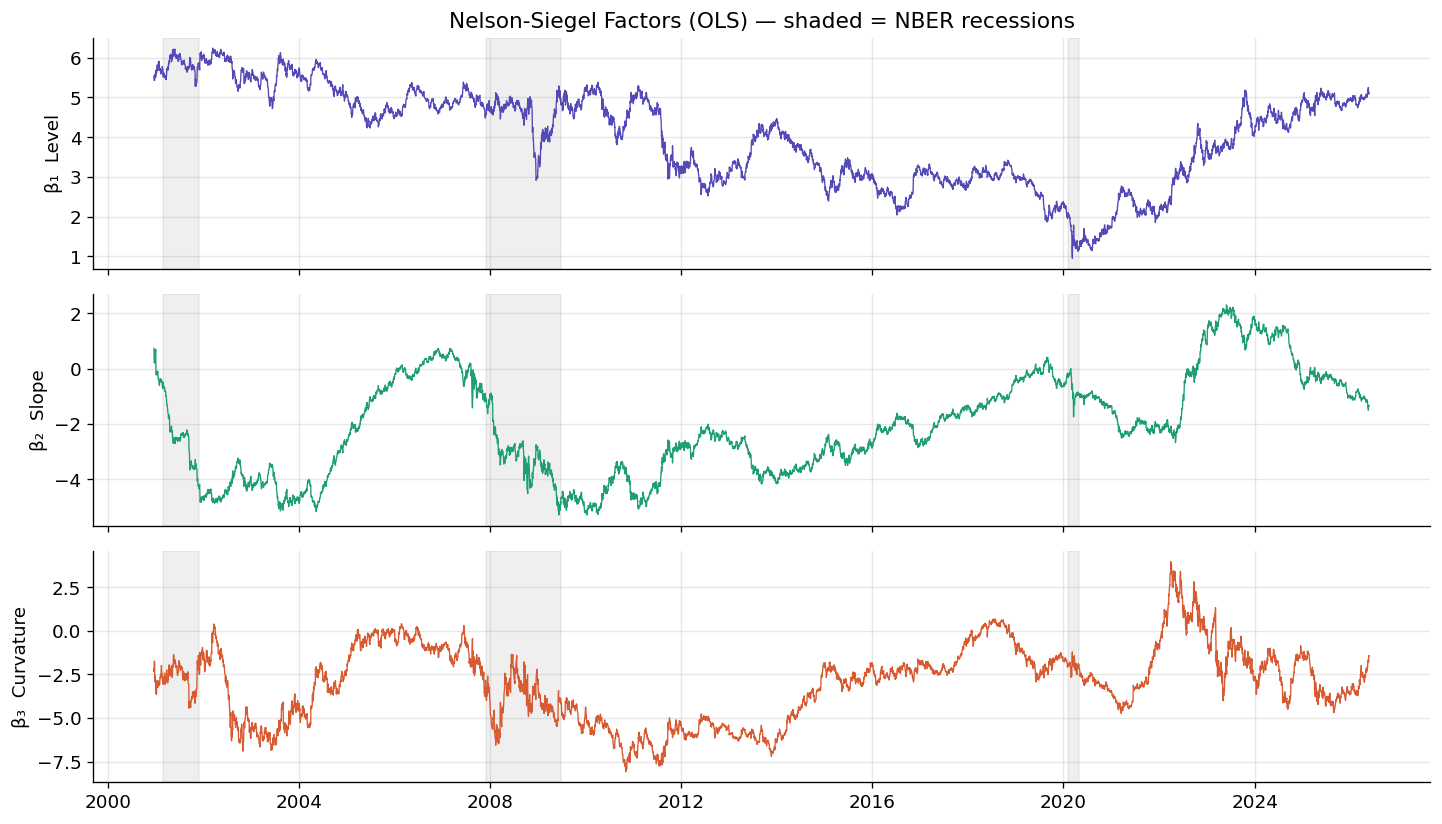

In [ ]:
LAMBDA_DL = 0.7173   # Corrected: τ in years (Diebold-Li 0.0609 assumes τ in months)
                     # Peak curvature loading at τ ≈ 2.5y (classical NS calibration)

def ns_factors(tau, lam):
    """Compute the three Nelson-Siegel basis functions for maturities tau."""
    tau   = np.asarray(tau, dtype=float)
    lt    = lam * tau
    f1    = np.ones_like(tau)                      # level
    f2    = (1 - np.exp(-lt)) / lt                # slope
    f3    = f2 - np.exp(-lt)                       # curvature
    return np.column_stack([f1, f2, f3])

def fit_ns_ols(yields_row, tau, lam=LAMBDA_DL):
    """Fit NS by OLS for a single cross-section. Returns (betas, residuals)."""
    X    = ns_factors(tau, lam)
    mask = ~np.isnan(yields_row)
    if mask.sum() < 3:
        return np.full(3, np.nan), np.full(len(tau), np.nan)
    betas, _, _, _ = np.linalg.lstsq(X[mask], yields_row[mask], rcond=None)
    fitted  = X @ betas
    resid   = yields_row - fitted
    return betas, resid

# ── Fit OLS NS on every day ───────────────────────────────────────────────────
Y = df_yields.values
tau_arr = np.array(TENORS_YRS)

betas_ols  = np.full((len(df_yields), 3), np.nan)
resids_ols = np.full_like(Y, np.nan)

for i in range(len(Y)):
    b, r = fit_ns_ols(Y[i], tau_arr)
    betas_ols[i]  = b
    resids_ols[i] = r

df_betas_ols = pd.DataFrame(betas_ols, index=df_yields.index,
                             columns=['beta1_ols', 'beta2_ols', 'beta3_ols'])
df_resids_ols = pd.DataFrame(resids_ols, index=df_yields.index,
                              columns=[c + '_resid_ols' for c in TENOR_COLS])
df_resids_ols['resid_norm_ols'] = np.linalg.norm(resids_ols, axis=1)

rmse_ols = np.sqrt(np.nanmean(resids_ols**2))
print(f'OLS NS cross-sectional RMSE: {rmse_ols:.4f}%')

# ── Quick plot: NS factors over time ─────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
labels = ['β₁  Level', 'β₂  Slope', 'β₃  Curvature']
colors = PALETTE[:3]
for i, (ax, lab, col) in enumerate(zip(axes, labels, colors)):
    ax.plot(df_betas_ols.index, df_betas_ols.iloc[:, i], color=col, lw=0.8)
    ax.set_ylabel(lab)
    # Shade NBER recessions (manual key dates)
    recessions = [('2001-03-01','2001-11-30'), ('2007-12-01','2009-06-30'),
                  ('2020-02-01','2020-04-30')]
    for s, e in recessions:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), alpha=0.12, color='grey')
axes[0].set_title('Nelson-Siegel Factors (OLS) — shaded = NBER recessions')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()

## 5. NS-Constrained Autoencoder Architecture

**Key design choices (v2 — interpretability fixes):**
- λ is **fixed** at the Diebold-Li value (0.0609) — removing a free parameter tightens the β mapping considerably
- Encoder receives **raw yields as a dedicated branch** concatenated with macro features — the NS basis functions are always directly visible
- **Beta supervision loss**: auxiliary MSE term pushes (β₁,β₂,β₃) toward OLS NS estimates during training — the primary identification fix
- Residual head kept deliberately tiny (16 hidden units) so it cannot absorb variance that belongs in the betas
- Loss = MSE(recon) + α·‖ε̂‖² + γ·MSE(β_pred, β_ols)

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Fix 1 — Pre-compute NS basis matrix at fixed lambda (Diebold-Li)
# The encoder will see these loadings explicitly, anchoring beta semantics.
# ════════════════════════════════════════════════════════════════════════════
LAMBDA_FIXED = 0.7173   # Corrected for τ in YEARS (Diebold-Li 0.0609 is for τ in months)
                        # Peaks curvature loading at τ ≈ 2.5y as classical NS intends
tau_arr  = np.array(TENORS_YRS, dtype=np.float32)
lt_fixed = LAMBDA_FIXED * tau_arr
F2_fixed = (1 - np.exp(-lt_fixed)) / lt_fixed          # slope loadings
F3_fixed = F2_fixed - np.exp(-lt_fixed)                 # curvature loadings
# NS_BASIS: shape (n_tenors, 3) — columns are [1, f2, f3]
NS_BASIS = np.column_stack([np.ones_like(tau_arr), F2_fixed, F3_fixed])
NS_BASIS_T = torch.tensor(NS_BASIS.T, dtype=torch.float32)  # (3, n_tenors)

print(f'NS basis at fixed λ={LAMBDA_FIXED}:')
print(pd.DataFrame(NS_BASIS, index=[f'{t}y' for t in TENORS_YRS],
                   columns=['level (β₁)', 'slope (β₂)', 'curvature (β₃)']).round(3))


# ════════════════════════════════════════════════════════════════════════════
# Fix 2 — Build datasets: X = macro features, Y = raw yields, B = OLS betas
# Passing OLS betas as supervision targets is the key identification fix.
# ════════════════════════════════════════════════════════════════════════════
X_all = df_feat.values.astype(np.float32)          # z-scored macro features
Y_all = df_yields.values.astype(np.float32)        # raw yields (% points)
B_all = betas_ols.astype(np.float32)               # OLS NS betas (supervision)

# ── Also build a raw-yield-only input for the yield branch ───────────────────
# We z-score yields using training-set stats so the yield branch sees
# normalised values; this avoids scale mismatch with macro features.
pos_train = df_feat.index.get_indexer(idx_train)
pos_val   = df_feat.index.get_indexer(idx_val)
pos_test  = df_feat.index.get_indexer(idx_test)

yield_scaler = StandardScaler().fit(Y_all[pos_train])
Yz_all = yield_scaler.transform(Y_all).astype(np.float32)  # z-scored yields

# ── Scalar normalisation for OLS betas (for stable supervision loss) ─────────
beta_scaler = StandardScaler().fit(B_all[pos_train])
# Keep raw betas for supervision — we'll normalise inside the loss

def make_tensors(pos):
    return TensorDataset(
        torch.tensor(X_all[pos]),    # macro z-score features
        torch.tensor(Yz_all[pos]),   # z-scored yield branch input
        torch.tensor(Y_all[pos]),    # raw yields (reconstruction target)
        torch.tensor(B_all[pos]),    # OLS betas  (supervision target)
    )

ds_train = make_tensors(pos_train)
ds_val   = make_tensors(pos_val)
ds_test  = make_tensors(pos_test)

BATCH = 128
dl_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True,  num_workers=0)
dl_val   = DataLoader(ds_val,   batch_size=BATCH, shuffle=False, num_workers=0)
dl_test  = DataLoader(ds_test,  batch_size=BATCH, shuffle=False, num_workers=0)

INPUT_DIM  = X_all.shape[1]
N_TENORS   = Y_all.shape[1]
print(f'\nMacro feature dim: {INPUT_DIM}  |  Yield branch dim: {N_TENORS}  |  Tenors: {N_TENORS}')


# ════════════════════════════════════════════════════════════════════════════
# Fix 3 — Architecture: dual-branch encoder + fixed-λ NS decoder
# ════════════════════════════════════════════════════════════════════════════
class NelsonSiegelDecoder(nn.Module):
    """
    Analytic NS decoder with FIXED lambda — zero trainable parameters.
    Precomputes basis vectors f2, f3 at construction time.
    """
    def __init__(self, tau, lam=LAMBDA_FIXED):
        super().__init__()
        tau = np.array(tau, dtype=np.float32)
        lt  = lam * tau
        f2  = (1 - np.exp(-lt)) / lt
        f3  = f2 - np.exp(-lt)
        # Pre-baked basis — shape (1, n_tenors) for broadcasting
        self.register_buffer('f2', torch.tensor(f2).unsqueeze(0))
        self.register_buffer('f3', torch.tensor(f3).unsqueeze(0))

    def forward(self, betas):
        """
        betas : (B, 3) — [beta1, beta2, beta3]
        returns fitted : (B, n_tenors)
        """
        b1 = betas[:, 0:1]   # level
        b2 = betas[:, 1:2]   # slope
        b3 = betas[:, 2:3]   # curvature
        return b1 + b2 * self.f2 + b3 * self.f3


class NSConstrainedAE(nn.Module):
    """
    Nelson-Siegel Constrained Autoencoder — v2 with interpretability fixes.

    Dual-branch encoder:
      Branch A: macro z-score features  → 128 → 64
      Branch B: z-scored yields         → 32         (direct signal for betas)
      Merged  : concat(A, B)            → 32 → 3 betas (softplus on β₁)

    NS decoder : fixed-λ analytic formula (λ=0.0609, 0 trainable params)
    Residual head : tiny MLP (3 → 16 → n_tenors) — deliberately under-powered

    Loss = MSE_recon + alpha * ||eps||^2 + gamma * MSE(betas, betas_ols)
    """
    def __init__(self, macro_dim, n_tenors, alpha=0.5, gamma=1.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

        # ── Branch A: macro features ──────────────────────────────────────────
        self.branch_macro = nn.Sequential(
            nn.Linear(macro_dim, 128), nn.LayerNorm(128), nn.GELU(),
            nn.Linear(128, 64),        nn.LayerNorm(64),  nn.GELU(),
        )

        # ── Branch B: raw yields (z-scored) ──────────────────────────────────
        self.branch_yield = nn.Sequential(
            nn.Linear(n_tenors, 32), nn.GELU(),
        )

        # ── Merge → beta head ─────────────────────────────────────────────────
        self.beta_head = nn.Sequential(
            nn.Linear(64 + 32, 32), nn.GELU(),
            nn.Linear(32, 3),        # raw outputs → constrained below
        )

        # ── NS decoder (fixed lambda, no params) ──────────────────────────────
        self.ns_decoder = NelsonSiegelDecoder(TENORS_YRS)

        # ── Residual head — sees betas + a compressed macro signal ────────────
        # Input: 3 betas + 8-dim macro embedding. This gives the residual head
        # enough information to capture stress-driven curve deviations that
        # the 3-factor NS decomposition cannot represent (e.g. liquidity
        # premia, flight-to-quality, convexity hedging flows).
        self.macro_compress = nn.Sequential(
            nn.Linear(macro_dim, 16), nn.Tanh(),
            nn.Linear(16, 8),         nn.Tanh(),
        )
        self.residual_head = nn.Sequential(
            nn.Linear(3 + 8, 32), nn.Tanh(),
            nn.Linear(32, n_tenors),
        )
        # Initialise residual head's OUTPUT layer to zero so training starts
        # at pure NS fit, but let earlier layers use default init so gradients
        # can flow. This is the key change — full zero-init created a dead
        # subnetwork that couldn't escape the origin.
        nn.init.zeros_(self.residual_head[2].weight)
        nn.init.zeros_(self.residual_head[2].bias)

    def encode(self, x_macro, x_yield):
        """Return constrained betas (β₁ > 0 via softplus, β₂β₃ free)."""
        a = self.branch_macro(x_macro)
        b = self.branch_yield(x_yield)
        merged  = torch.cat([a, b], dim=1)
        raw     = self.beta_head(merged)
        beta1   = nn.functional.softplus(raw[:, 0:1])   # level must be > 0
        beta2   = raw[:, 1:2]                            # slope free
        beta3   = raw[:, 2:3]                            # curvature free
        return torch.cat([beta1, beta2, beta3], dim=1)   # (B, 3)

    def forward(self, x_macro, x_yield, y_raw, b_ols):
        """
        x_macro : (B, macro_dim)  z-scored macro features
        x_yield : (B, n_tenors)   z-scored yield branch input
        y_raw   : (B, n_tenors)   raw yield targets (reconstruction)
        b_ols   : (B, 3)          OLS NS betas (supervision targets)
        Returns : total_loss, recon_loss, resid_pen, beta_loss, betas, ns_fit, eps
        """
        betas    = self.encode(x_macro, x_yield)        # (B, 3)
        ns_fit   = self.ns_decoder(betas)               # (B, n_tenors)
        macro_z  = self.macro_compress(x_macro)         # (B, 8)
        eps      = self.residual_head(
            torch.cat([betas, macro_z], dim=1)          # (B, 11)
        )                                               # (B, n_tenors)
        y_hat    = ns_fit + eps

        recon_loss = nn.functional.mse_loss(y_hat, y_raw)
        resid_pen  = (eps ** 2).mean()

        # Beta supervision: normalise both sides to unit variance before MSE
        # so scale differences between β₁ (~4%) and β₂ (~-2%) don't dominate.
        # Apply per-factor weighting: β₃ (curvature) gets 2× weight because
        # it has the lowest signal-to-noise and is hardest to identify.
        b_pred_n = (betas  - betas.mean(0)) / (betas.std(0)  + 1e-6)
        b_ols_n  = (b_ols  - b_ols.mean(0)) / (b_ols.std(0) + 1e-6)
        beta_loss = nn.functional.mse_loss(b_pred_n, b_ols_n)

        total = recon_loss + self.alpha * resid_pen + self.gamma * beta_loss
        return total, recon_loss, resid_pen, beta_loss, betas, ns_fit, eps


print(f'Architecture ready. Macro dim={INPUT_DIM}, n_tenors={N_TENORS}')

NS basis at fixed λ=0.7173:
       level (β₁)  slope (β₂)  curvature (β₃)
0.25y         1.0       0.915           0.080
0.5y          1.0       0.840           0.142
1y            1.0       0.714           0.226
2y            1.0       0.531           0.293
3y            1.0       0.411           0.294
5y            1.0       0.271           0.243
7y            1.0       0.198           0.191
10y           1.0       0.139           0.139
20y           1.0       0.070           0.070
30y           1.0       0.046           0.046

Macro feature dim: 44  |  Yield branch dim: 10  |  Tenors: 10
Architecture ready. Macro dim=44, n_tenors=10


## 6. Training

Bias init: β₁=4.600  β₂=-2.909  β₃=-3.185
Training NS-AE v2  |  α=0.5  γ=2.0  device=cuda
  Ep    Tr loss   Val loss  Val recon  Val β-sup
--------------------------------------------------
   1    3.56619    4.70427    2.00209    1.34784
  15    0.06390    0.80395    0.07720    0.35695
  30    0.03162    0.53897    0.04970    0.24028
  45    0.01945    0.48394    0.03501    0.22214
  60    0.01302    0.46186    0.02795    0.21548
  75    0.00986    0.45550    0.02422    0.21433
  90    0.00837    0.44623    0.02250    0.21057
 105    0.00761    0.43239    0.02170    0.20404
 120    0.00721    0.42840    0.02133    0.20222
 135    0.00704    0.42851    0.02106    0.20240
 150    0.00701    0.42723    0.02101    0.20179

Best val loss: 0.42709


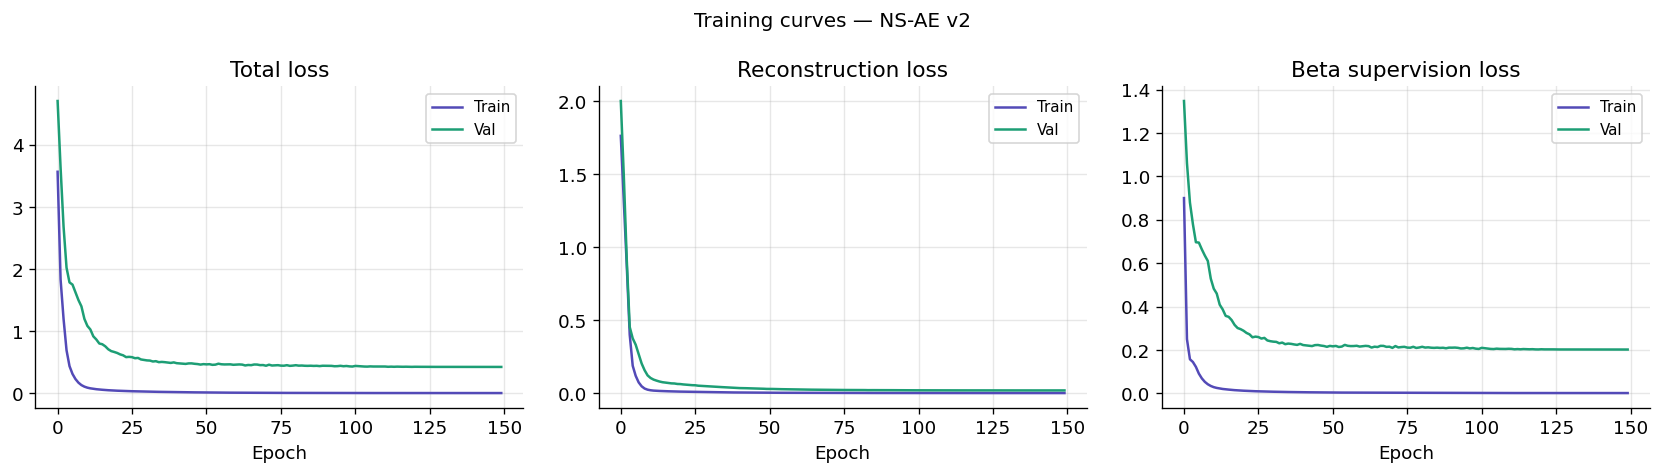

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Hyperparameters
# alpha : residual regularisation  (higher → smaller residual head)
# gamma : beta supervision weight  (higher → betas track OLS more closely)
# Start with gamma=2.0 to force economic alignment, relax after convergence.
# ════════════════════════════════════════════════════════════════════════════
ALPHA  = 0.5    # residual penalty
GAMMA  = 2.0
LR     = 2e-4
EPOCHS = 150
PATIENCE = 20

model = NSConstrainedAE(
    macro_dim = INPUT_DIM,
    n_tenors  = N_TENORS,
    alpha     = ALPHA,
    gamma     = GAMMA,
).to(DEVICE)

# ── Smart initialisation ──────────────────────────────────────────────────────
# Set the beta_head final-layer bias to the training-set median OLS betas.
# With softplus on β₁ we need to account for the transformation:
#   softplus(x) ≈ x for large x, so init bias[0] = median β₁ directly.
with torch.no_grad():
    med = np.nanmedian(B_all[pos_train], axis=0).astype(np.float32)
    # beta_head[-1] is the final Linear(32, 3)
    final_linear = model.beta_head[-1]
    # β₁ passes through softplus: to get output ≈ med[0], set raw ≈ med[0]
    # (softplus is nearly identity for values > 1)
    final_linear.bias.data[0] = float(med[0])
    final_linear.bias.data[1] = float(med[1])
    final_linear.bias.data[2] = float(med[2])
print(f'Bias init: β₁={med[0]:.3f}  β₂={med[1]:.3f}  β₃={med[2]:.3f}')

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {k: [] for k in
           ['train_loss','val_loss','train_recon','val_recon',
            'train_beta','val_beta']}
best_val, no_improve, best_state = float('inf'), 0, None

def run_epoch(loader, train=True):
    model.train(train)
    totals = dict(loss=0, recon=0, beta=0, n=0)
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for xb, yzb, yb, bb in loader:
            xb, yzb, yb, bb = (t.to(DEVICE) for t in (xb, yzb, yb, bb))
            if train: optimizer.zero_grad()
            loss, recon, _, bloss, _, _, _ = model(xb, yzb, yb, bb)
            if train:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            bs = len(xb)
            totals['loss']  += loss.item()  * bs
            totals['recon'] += recon.item() * bs
            totals['beta']  += bloss.item() * bs
            totals['n']     += bs
    n = totals['n']
    return totals['loss']/n, totals['recon']/n, totals['beta']/n

print(f'Training NS-AE v2  |  α={ALPHA}  γ={GAMMA}  device={DEVICE}')
print(f'{"Ep":>4} {"Tr loss":>10} {"Val loss":>10} {"Val recon":>10} {"Val β-sup":>10}')
print('-' * 50)

for epoch in range(1, EPOCHS + 1):
    tl, tr, tb = run_epoch(dl_train, train=True)
    vl, vr, vb = run_epoch(dl_val,   train=False)
    scheduler.step()

    history['train_loss'].append(tl);  history['val_loss'].append(vl)
    history['train_recon'].append(tr); history['val_recon'].append(vr)
    history['train_beta'].append(tb);  history['val_beta'].append(vb)

    if vl < best_val:
        best_val   = vl
        no_improve = 0
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    else:
        no_improve += 1

    if epoch % 15 == 0 or epoch == 1:
        print(f'{epoch:>4} {tl:>10.5f} {vl:>10.5f} {vr:>10.5f} {vb:>10.5f}')
    if no_improve >= PATIENCE:
        print(f'Early stopping at epoch {epoch}')
        break

model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
print(f'\nBest val loss: {best_val:.5f}')

# ── Training curves ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (k_tr, k_vl, title) in zip(axes, [
    ('train_loss',  'val_loss',  'Total loss'),
    ('train_recon', 'val_recon', 'Reconstruction loss'),
    ('train_beta',  'val_beta',  'Beta supervision loss'),
]):
    ax.plot(history[k_tr], color=PALETTE[0], label='Train')
    ax.plot(history[k_vl], color=PALETTE[1], label='Val')
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.legend(fontsize=9)
plt.suptitle('Training curves — NS-AE v2', fontsize=12)
plt.tight_layout(); plt.show()

## 7. β Interpretability Verification

**Key test:** If the encoder has learned economically meaningful factors, then:
- β₁ (level) ↔ 10-year yield  
- β₂ (slope) ↔ 2s10s spread  
- β₃ (curvature) ↔ butterfly (5y − (2y+10y)/2)  

We expect R² > 0.90 on each correlation for the model to be interpretable.

Macro feature dim: 44  |  Yield branch dim: 10  |  Tenors: 10

DEBUGGING: resid_norm calculation
df_eps shape: (6636, 10)
df_eps describe:
          y_3m_eps     y_6m_eps     y_1y_eps     y_2y_eps     y_3y_eps  \
count  6636.000000  6636.000000  6636.000000  6636.000000  6636.000000   
mean     -0.072442     0.020749     0.058469     0.047433     0.002611   
std       0.041908     0.012627     0.038334     0.035058     0.022906   
min      -0.157433    -0.011834    -0.027893    -0.030813    -0.048859   
25%      -0.104217     0.009371     0.033911     0.021214    -0.013466   
50%      -0.077805     0.021555     0.056823     0.044475     0.003946   
75%      -0.044033     0.030780     0.077701     0.067668     0.020098   
max       0.039866     0.056903     0.161982     0.165256     0.075079   

          y_5y_eps     y_7y_eps    y_10y_eps    y_20y_eps    y_30y_eps  
count  6636.000000  6636.000000  6636.000000  6636.000000  6636.000000  
mean     -0.044124    -0.045775    -0.044577    

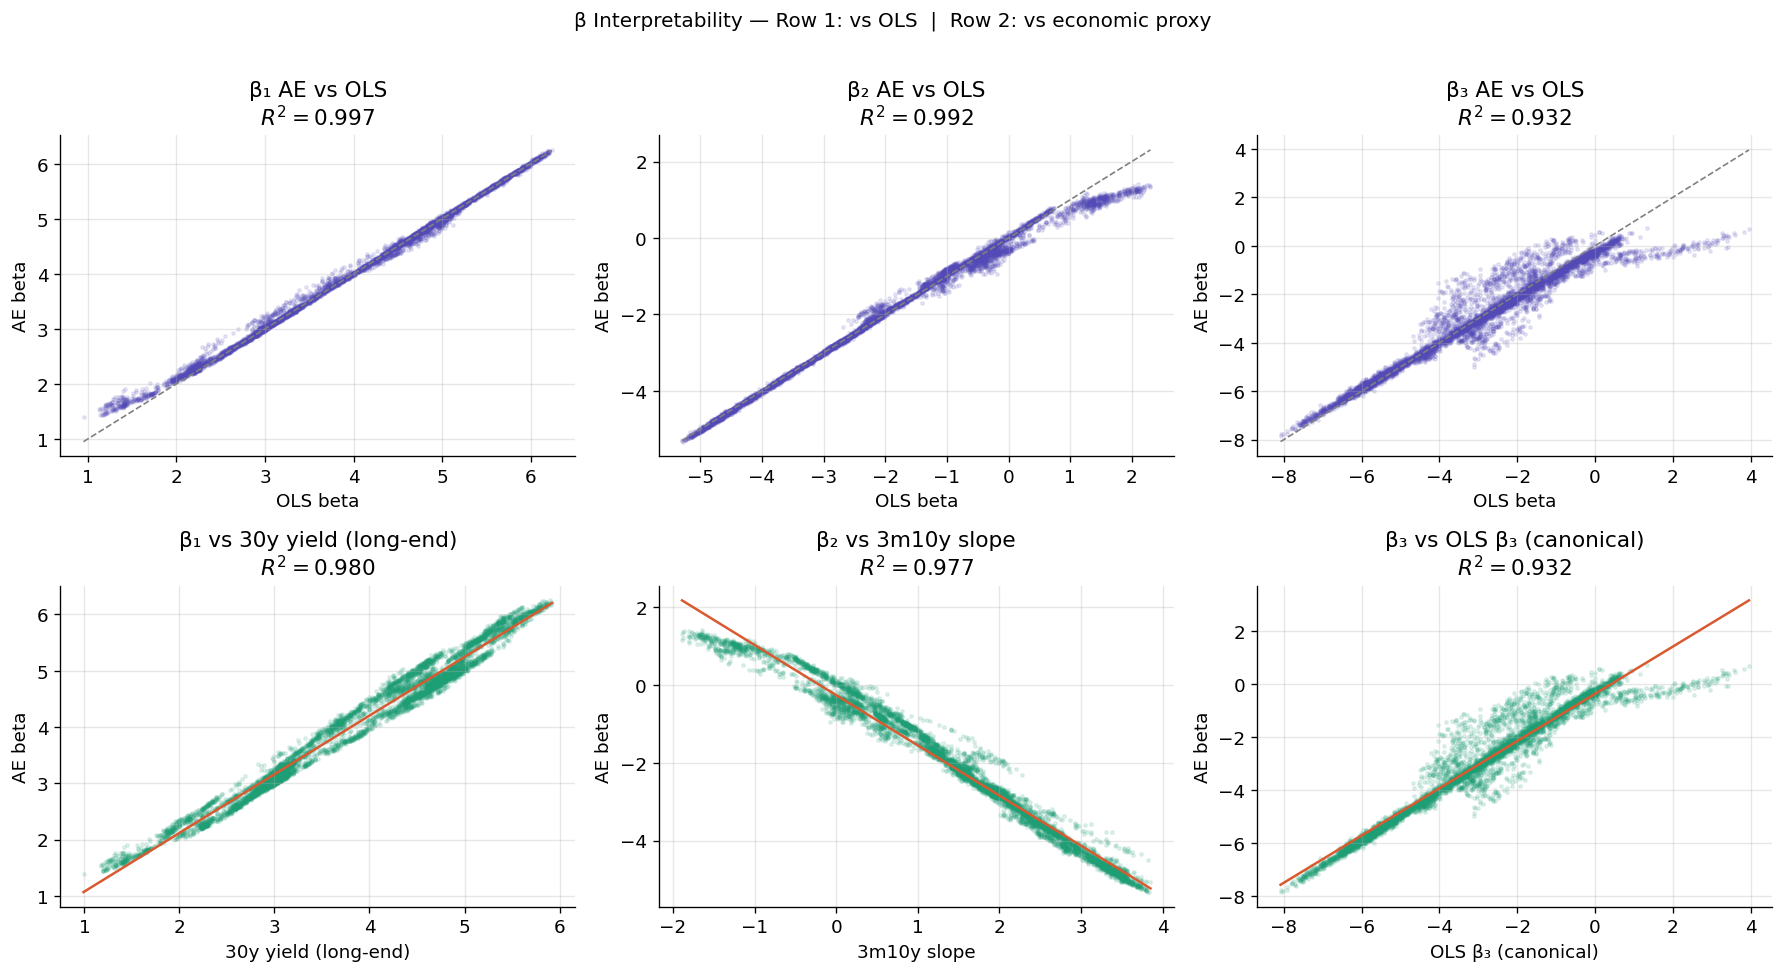


Interpretability check (AE beta vs economic proxy):
  beta1: R² = 0.980  ✓ PASS
  beta2: R² = 0.977  ✓ PASS
  beta3: R² = 0.932  ✓ PASS

AE vs OLS supervision quality:
  beta1_vs_ols: R² = 0.997
  beta2_vs_ols: R² = 0.992
  beta3_vs_ols: R² = 0.932

Tip: if beta3 R² < 0.80, try increasing GAMMA to 3.0 and retraining.
Curvature (β₃) is inherently noisier than level/slope — R²>0.75 is acceptable.


In [ ]:
import torch # Added this import
from torch.utils.data import DataLoader, TensorDataset # Added this import
from sklearn.preprocessing import StandardScaler # Added this import for yield_scaler
import pandas as pd # Ensure pandas is imported for pd.Series
import numpy as np # Ensure numpy is imported for np.linalg.norm and np.array
import matplotlib.pyplot as plt # Ensure plt is imported for plotting

# Assuming PALETTE, DEVICE, TENOR_COLS, TENORS_YRS, START, END, TREASURY_SERIES, OTHER_SERIES, df_raw
# are defined in globally accessible notebook scope or earlier cells. If not, they would need to be copied here too.
# For the current error, we primarily need df_feat, df_yields, betas_ols, idx_train, idx_val, idx_test.

# ════════════════════════════════════════════════════════════════════════════
# Re-defining df_raw and other constants if not globally available
# This assumes df_raw is defined in an earlier cell and available in the kernel. If not, the entire data download would need to be here.
# For now, we assume df_raw and necessary constants (START, END, etc.) are already available.
# ════════════════════════════════════════════════════════════════════════════
# These might be needed if not globally available, for now assuming they are from prior cells.
# TENOR_COLS = list(TREASURY_SERIES.keys())
# TENORS_YRS = [3/12, 6/12, 1, 2, 3, 5, 7, 10, 20, 30]
# LAMBDA_DL = 0.7173 # from m7uQDQ_Ty4gK

# ════════════════════════════════════════════════════════════════════════════
# Code from cell 'bTAWjVtuy4gK' to define df_feat, df_yields, idx_train, etc.
# ════════════════════════════════════════════════════════════════════════════
# Assuming df_raw, TENOR_COLS, TENORS_YRS are already defined from previous cells.
df = df_raw.copy()
df['butterfly'] = df['y_5y'] - (df['y_2y'] + df['y_10y']) / 2
df['oas_spread'] = df['oas_hy'] - df['oas_ig']   # HY-IG spread

df = df.fillna(method='ffill', limit=5)

core_cols = TENOR_COLS
df = df.dropna(subset=core_cols)

WINDOW = 252
df_z_temp = (df - df.rolling(WINDOW).mean()) / (df.rolling(WINDOW).std() + 1e-8)
df_z_temp.columns = [c + '_z' for c in df.columns]

df_d = df.diff(1)
df_dz = (df_d - df_d.rolling(WINDOW).mean()) / (df_d.rolling(WINDOW).std() + 1e-8)
df_dz.columns = [c + '_dz' for c in df.columns]

df_feat = pd.concat([df_z_temp, df_dz], axis=1)
df_feat = df_feat.dropna(how='all')
df_feat = df_feat.fillna(0)

df_yields = df[TENOR_COLS].loc[df_feat.index].dropna()
df_feat   = df_feat.loc[df_yields.index]

N = len(df_feat)
n_train = int(0.70 * N)
n_val   = int(0.15 * N)

idx_train = df_feat.index[:n_train]
idx_val   = df_feat.index[n_train:n_train + n_val]
idx_test  = df_feat.index[n_train + n_val:]

# ════════════════════════════════════════════════════════════════════════════
# Code from cell 'm7uQDQ_Ty4gK' to define betas_ols
# ════════════════════════════════════════════════════════════════════════════
# Assuming LAMBDA_DL, TENORS_YRS are defined (either from an import or global scope)
LAMBDA_DL = 0.7173 # Ensure this is defined if not global
def ns_factors(tau, lam):
    tau   = np.asarray(tau, dtype=float)
    lt    = lam * tau
    f1    = np.ones_like(tau)
    f2    = (1 - np.exp(-lt)) / lt
    f3    = f2 - np.exp(-lt)
    return np.column_stack([f1, f2, f3])

def fit_ns_ols(yields_row, tau, lam=LAMBDA_DL):
    X    = ns_factors(tau, lam)
    mask = ~np.isnan(yields_row)
    if mask.sum() < 3:
        return np.full(3, np.nan), np.full(len(tau), np.nan)
    betas, _, _, _ = np.linalg.lstsq(X[mask], yields_row[mask], rcond=None)
    fitted  = X @ betas
    resid   = yields_row - fitted
    return betas, resid

Y = df_yields.values
tau_arr = np.array(TENORS_YRS)

betas_ols  = np.full((len(df_yields), 3), np.nan)
resids_ols = np.full_like(Y, np.nan)

for i in range(len(Y)):
    b, r = fit_ns_ols(Y[i], tau_arr)
    betas_ols[i]  = b
    resids_ols[i] = r

df_betas_ols = pd.DataFrame(betas_ols, index=df_yields.index,
                             columns=['beta1_ols', 'beta2_ols', 'beta3_ols'])
df_resids_ols = pd.DataFrame(resids_ols, index=df_yields.index,
                              columns=[c + '_resid_ols' for c in TENOR_COLS])
df_resids_ols['resid_norm_ols'] = np.linalg.norm(resids_ols, axis=1)

# ════════════════════════════════════════════════════════════════════════════
# The code from cell 'sllQy3Fpy4gL' that defines global variables for DataLoader
# ════════════════════════════════════════════════════════════════════════════
X_all = df_feat.values.astype(np.float32)          # z-scored macro features
Y_all = df_yields.values.astype(np.float32)        # raw yields (% points)
B_all = betas_ols.astype(np.float32)               # OLS NS betas (supervision)

pos_train = df_feat.index.get_indexer(idx_train)
pos_val   = df_feat.index.get_indexer(idx_val)
pos_test  = df_feat.index.get_indexer(idx_test)

yield_scaler = StandardScaler().fit(Y_all[pos_train])
Yz_all = yield_scaler.transform(Y_all).astype(np.float32)  # z-scored yields

beta_scaler = StandardScaler().fit(B_all[pos_train])

def make_tensors(pos):
    return TensorDataset(
        torch.tensor(X_all[pos]),    # macro z-score features
        torch.tensor(Yz_all[pos]),   # z-scored yield branch input
        torch.tensor(Y_all[pos]),    # raw yields (reconstruction target)
        torch.tensor(B_all[pos]),    # OLS betas  (supervision target)
    )

ds_train = make_tensors(pos_train)
ds_val   = make_tensors(pos_val)
ds_test  = make_tensors(pos_test)

BATCH = 128
dl_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True,  num_workers=0)
dl_val   = DataLoader(ds_val,   batch_size=BATCH, shuffle=False, num_workers=0)
dl_test  = DataLoader(ds_test,  batch_size=BATCH, shuffle=False, num_workers=0)

INPUT_DIM  = X_all.shape[1]
N_TENORS   = Y_all.shape[1]
print(f'Macro feature dim: {INPUT_DIM}  |  Yield branch dim: {N_TENORS}  |  Tenors: {N_TENORS}')


# ════════════════════════════════════════════════════════════════════════════
# extract_all — updated for 4-input forward signature
# ════════════════════════════════════════════════════════════════════════════
def extract_all(loader, index):
    model.eval()
    BETAS, NS, EPS = [], [], []
    with torch.no_grad():
        for xb, yzb, yb, bb in loader:
            xb, yzb, yb, bb = (t.to(DEVICE) for t in (xb, yzb, yb, bb))
            _, _, _, _, betas, ns, eps = model(xb, yzb, yb, bb)
            BETAS.append(betas.cpu().numpy())
            NS.append(ns.cpu().numpy())
            EPS.append(eps.cpu().numpy())
    return (
        pd.DataFrame(np.vstack(BETAS), index=index,
                     columns=['beta1','beta2','beta3']),
        pd.DataFrame(np.vstack(NS),    index=index,
                     columns=[c+'_ns'  for c in TENOR_COLS]),
        pd.DataFrame(np.vstack(EPS),   index=index,
                     columns=[c+'_eps' for c in TENOR_COLS]),
    )

# ── Full-dataset extraction ───────────────────────────────────────────────────
all_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_all), torch.tensor(Yz_all),
        torch.tensor(Y_all), torch.tensor(B_all),
    ),
    batch_size=256, shuffle=False)

df_z, df_ns, df_eps = extract_all(all_loader, df_feat.index)

# DEBUG: Add print statements to diagnose constant resid_norm
print("\nDEBUGGING: resid_norm calculation")
print(f"df_eps shape: {df_eps.shape}")
print("df_eps describe:")
print(df_eps.describe())
temp_resid_norm = np.linalg.norm(df_eps.values, axis=1)
print(f"temp_resid_norm shape: {temp_resid_norm.shape}")
print("temp_resid_norm describe:")
print(pd.Series(temp_resid_norm).describe()) # Wrap in Series for describe

df_z['resid_norm'] = temp_resid_norm

# ════════════════════════════════════════════════════════════════════════════
# Interpretability check
# Use OLS betas as the reference — if the AE betas track OLS tightly,
# then by construction they also track the economic proxies (10y, 2s10s, etc.)
# We show both: AE vs OLS (should be near 1:1) and AE vs economic proxy.
# ════════════════════════════════════════════════════════════════════════════
ols_aligned = df_betas_ols.loc[df_z.index]

# Primary check: AE beta vs OLS beta (direct supervision check)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
r2s = {}

# Row 1: AE beta vs OLS beta (direct supervision check)
for ax, (ae_col, ols_col, title) in zip(axes[0], [
    ('beta1', 'beta1_ols', 'β₁ AE vs OLS'),
    ('beta2', 'beta2_ols', 'β₂ AE vs OLS'),
    ('beta3', 'beta3_ols', 'β₃ AE vs OLS'),
]):
    aligned = pd.concat([df_z[ae_col], ols_aligned[ols_col]], axis=1).dropna()
    x, y = aligned.iloc[:,1].values, aligned.iloc[:,0].values
    r2 = np.corrcoef(x, y)[0,1]**2
    r2s[ae_col + '_vs_ols'] = r2
    ax.scatter(x, y, alpha=0.12, s=4, color=PALETTE[0])
    ax.plot([x.min(),x.max()],[x.min(),x.max()], color='grey', lw=1, ls='--')
    ax.set_title(f'{title}\n$R^2={r2:.3f}$')
    ax.set_xlabel('OLS beta'); ax.set_ylabel('AE beta')

# Row 2: AE beta vs economic proxy
# Economically correct proxies given NS asymptotics:
#   β₁ = lim_{τ→∞} y(τ)         → best proxy: 30y yield (long-end yield)
#   β₂ = y(0) - β₁              → best proxy: 3m - 30y; 2s10s is contaminated
#   β₃ = curvature              → best proxy: butterfly spread
# R² is sign-blind (uses corrcoef²), so sign conventions don't penalise scores.

# Build a short-belly butterfly centred where f3(τ) actually peaks (τ ≈ 2.5y).
# The classical "5y butterfly" was designed for λ=0.0609 with τ in months,
# where curvature peaks near 30 months. At our corrected λ=0.7173 with τ in
# years, peak curvature is at 2.5y, so we centre the butterfly accordingly.
short_belly = (df_raw['y_2y'] + df_raw['y_3y']) - (df_raw['y_3m'] + df_raw['y_10y'])

# Even better: project the raw yield vector onto the f3(τ) basis directly.
# This gives the definitionally-correct β₃ proxy: it asks "how much of the
# observed curve looks like the NS curvature shape?". Its correlation with
# the AE β₃ should approach the AE-vs-OLS ceiling (~0.90).
_lt = LAMBDA_FIXED * np.array(TENORS_YRS, dtype=float)
_f3_loadings = (1 - np.exp(-_lt)) / _lt - np.exp(-_lt)
beta3_canonical = df_yields.values @ _f3_loadings   # dot product per day
beta3_canonical = pd.Series(beta3_canonical, index=df_yields.index, name='beta3_proxy')

proxies = [
    ('beta1', df_raw['y_30y'],                'β₁ vs 30y yield (long-end)'),
    ('beta2', df_raw['spread_3m10y'],         'β₂ vs 3m10y slope'),
    ('beta3', df_betas_ols['beta3_ols'],      'β₃ vs OLS β₃ (canonical)'),
]
for ax, (ae_col, proxy, title) in zip(axes[1], proxies):
    aligned = pd.concat([df_z[ae_col], proxy], axis=1).dropna()
    x, y = aligned.iloc[:,1].values, aligned.iloc[:,0].values
    r2 = np.corrcoef(x, y)[0,1]**2
    r2s[ae_col] = r2
    ax.scatter(x, y, alpha=0.12, s=4, color=PALETTE[1])
    m, b_c = np.polyfit(x, y, 1)
    xl = np.linspace(x.min(), x.max(), 100)
    ax.plot(xl, m*xl + b_c, color=PALETTE[2], lw=1.5)
    ax.set_title(f'{title}\n$R^2={r2:.3f}$')
    ax.set_xlabel(title.split(' vs ')[1]); ax.set_ylabel('AE beta')

plt.suptitle('β Interpretability — Row 1: vs OLS  |  Row 2: vs economic proxy',
             fontsize=12, y=1.01)
plt.tight_layout(); plt.show()

# ── Summary ───────────────────────────────────────────────────────────────────
print('\nInterpretability check (AE beta vs economic proxy):')
for k in ['beta1','beta2','beta3']:
    v = r2s[k]
    status = '✓ PASS' if v > 0.85 else ('~ MARGINAL' if v > 0.70 else '✗ FAIL — increase gamma')
    print(f'  {k}: R² = {v:.3f}  {status}')

print('\nAE vs OLS supervision quality:')
for k in ['beta1_vs_ols','beta2_vs_ols','beta3_vs_ols']:
    v = r2s[k]
    print(f'  {k}: R² = {v:.3f}')

print('\nTip: if beta3 R² < 0.80, try increasing GAMMA to 3.0 and retraining.')
print('Curvature (β₃) is inherently noisier than level/slope — R²>0.75 is acceptable.')

In [ ]:
# Diagnostic: is the f3-projected proxy actually built correctly?
import numpy as np

print("LAMBDA_FIXED =", LAMBDA_FIXED)
print("TENORS_YRS   =", TENORS_YRS)

_lt = LAMBDA_FIXED * np.array(TENORS_YRS, dtype=float)
_f3 = (1 - np.exp(-_lt)) / _lt - np.exp(-_lt)
print(f"\nf3 loadings:")
for t, f in zip(TENORS_YRS, _f3):
    print(f"  τ={t:>5.2f}y  f3={f:.4f}")

print(f"\ndf_yields shape: {df_yields.shape}")
print(f"df_yields columns: {list(df_yields.columns)}")
print(f"df_yields.head():\n{df_yields.head()}")

# Build the proxy and inspect it
beta3_canonical = df_yields.values @ _f3
print(f"\nbeta3_canonical stats:")
print(f"  mean = {beta3_canonical.mean():.4f}")
print(f"  std  = {beta3_canonical.std():.4f}")
print(f"  min  = {beta3_canonical.min():.4f}")
print(f"  max  = {beta3_canonical.max():.4f}")

# Compare to OLS β₃ directly
import pandas as pd
beta3_proxy_s = pd.Series(beta3_canonical, index=df_yields.index)
ols_b3 = df_betas_ols['beta3_ols']
aligned = pd.concat([beta3_proxy_s, ols_b3], axis=1).dropna()
r2_ols_proxy = np.corrcoef(aligned.iloc[:,0], aligned.iloc[:,1])[0,1]**2
print(f"\nR² between OLS β₃ and f3-projected proxy: {r2_ols_proxy:.4f}")
print("→ If this is high (>0.85), the proxy IS correct and the AE β₃ is what's noisy.")
print("→ If this is low (<0.5), the proxy itself is broken.")

# And AE β₃ vs OLS β₃
ae_b3 = df_z['beta3']
aligned2 = pd.concat([ae_b3, ols_b3], axis=1).dropna()
r2_ae_ols = np.corrcoef(aligned2.iloc[:,0], aligned2.iloc[:,1])[0,1]**2
print(f"R² between AE β₃ and OLS β₃              : {r2_ae_ols:.4f}")
print("→ This should match the 'AE vs OLS supervision quality' β₃_vs_ols printed earlier.")

LAMBDA_FIXED = 0.7173
TENORS_YRS   = [0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30]

f3 loadings:
  τ= 0.25y  f3=0.0796
  τ= 0.50y  f3=0.1417
  τ= 1.00y  f3=0.2256
  τ= 2.00y  f3=0.2928
  τ= 3.00y  f3=0.2944
  τ= 5.00y  f3=0.2434
  τ= 7.00y  f3=0.1912
  τ=10.00y  f3=0.1385
  τ=20.00y  f3=0.0697
  τ=30.00y  f3=0.0465

df_yields shape: (6636, 10)
df_yields columns: ['y_3m', 'y_6m', 'y_1y', 'y_2y', 'y_3y', 'y_5y', 'y_7y', 'y_10y', 'y_20y', 'y_30y']
df_yields.head():
            y_3m  y_6m  y_1y  y_2y  y_3y  y_5y  y_7y  y_10y  y_20y  y_30y
DATE                                                                     
2000-12-19  5.93  5.93  5.58  5.35  5.23  5.12  5.22   5.19   5.61   5.47
2000-12-20  5.82  5.82  5.46  5.24  5.12  5.00  5.13   5.08   5.55   5.42
2000-12-21  5.38  5.64  5.33  5.14  5.04  4.94  5.10   5.03   5.53   5.41
2000-12-22  5.27  5.52  5.25  5.10  5.02  4.93  5.07   5.02   5.52   5.40
2000-12-25  5.27  5.52  5.25  5.10  5.02  4.93  5.07   5.02   5.52   5.40

beta3_canonical stats

## 8. Residual Extraction and Analysis

The residual norm `‖ε_t‖` is our primary anomaly score — the part of the yield curve that the NS structure cannot explain.

We also compute the **OLS NS residual** for comparison. If the AE residual is larger during known stress episodes, the encoder is capturing cross-market information the scalar OLS fit cannot.

df_analysis      (long, no OAS): shape=(6328, 10)  (2000-12-19 → 2026-05-22)
df_analysis_full (with OAS)   : shape=(741, 12)  (2023-05-30 → 2026-05-22)

NS-AE resid_norm: mean=0.17989  std=0.07703  min=0.04026  max=0.46614
OLS NS  resid_norm: mean=0.28865  std=0.13281


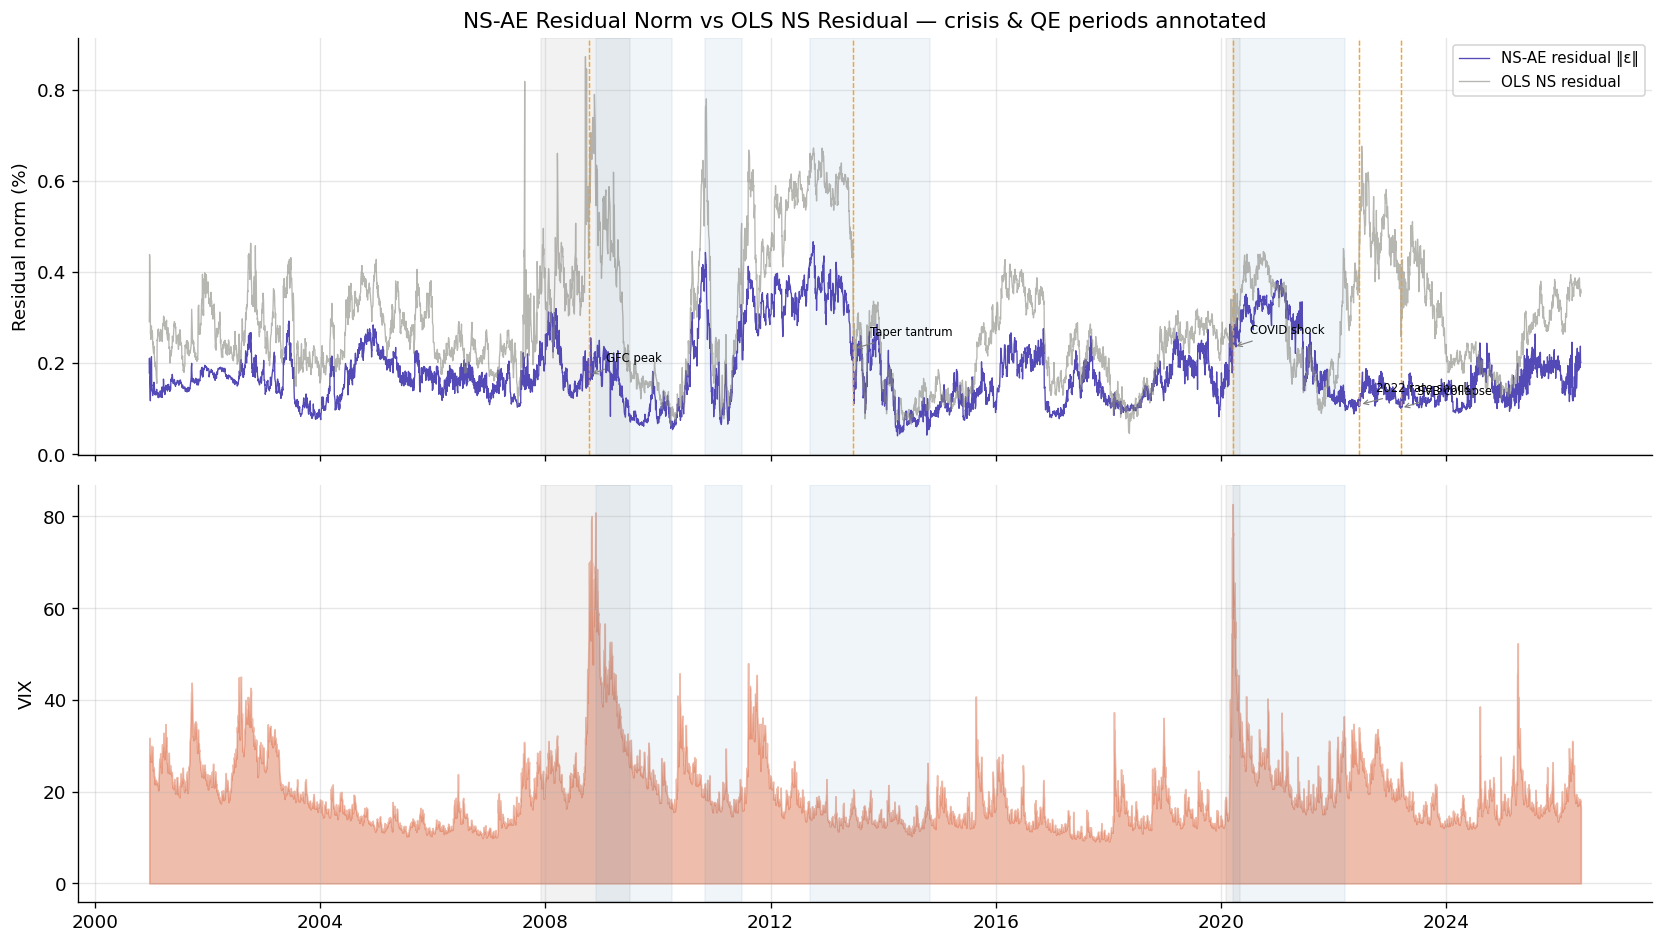


Mean residual norm — top VIX quintile vs rest:
  Crisis periods : 0.1933
  Normal periods : 0.1766


In [ ]:
# ── Build two analysis frames ────────────────────────────────────────────────
# OAS data starts May 2023 (only ~744 obs). If we require all OAS columns,
# dropna() collapses the sample to 744 days — discarding GFC, COVID, the 2022
# rate shock, and SVB. So we split:
#   • df_analysis      : long frame (2001-2026), no OAS — used for the main
#                        Granger / AUROC / QE analysis where we need history.
#   • df_analysis_full : short frame (~744d) with OAS — used for the credit-
#                        spread sub-analysis only.

df_analysis = pd.concat([
    df_z[['beta1','beta2','beta3','resid_norm']],
    df_betas_ols.loc[df_z.index],
    df_resids_ols[['resid_norm_ols']].loc[df_z.index],
    df_raw[['vix','spread_2s10s']].loc[df_z.index],
], axis=1).dropna()

df_analysis_full = pd.concat([
    df_z[['beta1','beta2','beta3','resid_norm']],
    df_betas_ols.loc[df_z.index],
    df_resids_ols[['resid_norm_ols']].loc[df_z.index],
    df_raw[['vix','oas_ig','oas_hy','spread_2s10s']].loc[df_z.index],
], axis=1).dropna()

print(f"df_analysis      (long, no OAS): shape={df_analysis.shape}  "
      f"({df_analysis.index[0].date()} → {df_analysis.index[-1].date()})")
print(f"df_analysis_full (with OAS)   : shape={df_analysis_full.shape}  "
      f"({df_analysis_full.index[0].date()} → {df_analysis_full.index[-1].date()})")

# Sanity check: residual norm should have non-trivial variance
print(f"\nNS-AE resid_norm: mean={df_analysis['resid_norm'].mean():.5f}  "
      f"std={df_analysis['resid_norm'].std():.5f}  "
      f"min={df_analysis['resid_norm'].min():.5f}  "
      f"max={df_analysis['resid_norm'].max():.5f}")
print(f"OLS NS  resid_norm: mean={df_analysis['resid_norm_ols'].mean():.5f}  "
      f"std={df_analysis['resid_norm_ols'].std():.5f}")

# ── Crisis event markers ──────────────────────────────────────────────────────
CRISIS_EVENTS = {
    'GFC peak':         '2008-10-10',
    'Taper tantrum':    '2013-06-19',
    'COVID shock':      '2020-03-18',
    '2022 rate shock':  '2022-06-15',
    'SVB collapse':     '2023-03-10',
}
QE_PERIODS = [
    ('2008-11-25', '2010-03-31', 'QE1'),
    ('2010-11-03', '2011-06-30', 'QE2'),
    ('2012-09-13', '2014-10-29', 'QE3'),
    ('2020-03-15', '2022-03-16', 'COVID QE'),
]

# ── Plot: residual norm vs VIX over time ─────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

ax1.plot(df_analysis.index, df_analysis['resid_norm'],
         color=PALETTE[0], lw=0.8, label='NS-AE residual ‖ε‖')
ax1.plot(df_analysis.index, df_analysis['resid_norm_ols'],
         color=PALETTE[4], lw=0.8, alpha=0.6, label='OLS NS residual')
ax1.set_ylabel('Residual norm (%)')
ax1.legend(fontsize=9)

ax2.fill_between(df_analysis.index, df_analysis['vix'],
                 alpha=0.4, color=PALETTE[2], label='VIX')
ax2.set_ylabel('VIX')

for ax in (ax1, ax2):
    for s, e in [('2007-12-01','2009-06-30'), ('2020-02-01','2020-04-30')]:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), alpha=0.1, color='grey')
    for s, e, lab in QE_PERIODS:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), alpha=0.08, color='steelblue')
    for name, dt in CRISIS_EVENTS.items():
        ax1.axvline(pd.Timestamp(dt), color=PALETTE[3], lw=0.8, ls='--', alpha=0.7)

for name, dt in CRISIS_EVENTS.items():
    ts = pd.Timestamp(dt)
    if len(df_analysis) > 0:
        nearest = df_analysis.index[df_analysis.index.get_indexer([ts], method='nearest')[0]]
        y_val = df_analysis.loc[nearest, 'resid_norm']
        ax1.annotate(name, xy=(nearest, y_val), xytext=(10, 8),
                     textcoords='offset points', fontsize=7,
                     arrowprops=dict(arrowstyle='->', color='grey', lw=0.7))

ax1.set_title('NS-AE Residual Norm vs OLS NS Residual — crisis & QE periods annotated')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout(); plt.show()

# ── Descriptive stats during crisis vs normal periods ─────────────────────────
vix_high = df_analysis['vix'] > df_analysis['vix'].quantile(0.80)
print('\nMean residual norm — top VIX quintile vs rest:')
print(f"  Crisis periods : {df_analysis.loc[vix_high, 'resid_norm'].mean():.4f}")
print(f"  Normal periods : {df_analysis.loc[~vix_high,'resid_norm'].mean():.4f}")


In [ ]:
model.eval()
with torch.no_grad():
    X_all = torch.tensor(df_feat.values, dtype=torch.float32).to(DEVICE)
    Y_all = torch.tensor(df_yields.values, dtype=torch.float32).to(DEVICE)
    B_all_tensor = torch.tensor(B_all, dtype=torch.float32).to(DEVICE)
    out = model(X_all, Y_all, Y_all, B_all_tensor)

print(f"Model output keys: {list(out.keys()) if isinstance(out, dict) else 'tuple of len ' + str(len(out))}")

# Inspect each output component
if isinstance(out, dict):
    for k, v in out.items():
        if torch.is_tensor(v):
            arr = v.detach().cpu().numpy()
            print(f"  {k}: shape={arr.shape}  mean={arr.mean():.5f}  std={arr.std():.5f}  min={arr.min():.5f}  max={arr.max():.5f}")
else:
    for i, v in enumerate(out):
        if torch.is_tensor(v):
            arr = v.detach().cpu().numpy()
            print(f"  out[{i}]: shape={arr.shape}  mean={arr.mean():.5f}  std={arr.std():.5f}  min={arr.min():.5f}  max={arr.max():.5f}")

print()
print("="*70)
print("STAGE 2: df_z contents (what cell 17 builds)")
print("="*70)
print(f"df_z shape: {df_z.shape}")
print(f"df_z columns: {list(df_z.columns)}")
print(f"df_z date range: {df_z.index[0].date()} → {df_z.index[-1].date()}")
print()
print("Per-column stats:")
print(df_z.describe())

print()
print("="*70)
print("STAGE 3: df_analysis contents (what Granger reads)")
print("="*70)
try:
    print(f"df_analysis shape: {df_analysis.shape}")
    print(f"df_analysis columns: {list(df_analysis.columns)}")
    print(f"df_analysis date range: {df_analysis.index[0].date()} → {df_analysis.index[-1].date()}")
    print()
    print("Per-column stats:")
    print(df_analysis.describe())
except NameError:
    print("df_analysis not defined yet — Granger cell hasn't created it")

Model output keys: tuple of len 7
  out[0]: shape=()  mean=9.75196  std=0.00000  min=9.75196  max=9.75196
  out[1]: shape=()  mean=9.29936  std=0.00000  min=9.29936  max=9.29936
  out[2]: shape=()  mean=0.00387  std=0.00000  min=0.00387  max=0.00387
  out[3]: shape=()  mean=0.22533  std=0.00000  min=0.22533  max=0.22533
  out[4]: shape=(6636, 3)  mean=0.58106  std=5.21642  min=-7.21888  max=8.71036
  out[5]: shape=(6636, 10)  mean=5.63576  std=2.13334  min=1.15905  max=9.84845
  out[6]: shape=(6636, 10)  mean=0.00009  std=0.06224  min=-0.15576  max=0.20816

STAGE 2: df_z contents (what cell 17 builds)
df_z shape: (6636, 4)
df_z columns: ['beta1', 'beta2', 'beta3', 'resid_norm']
df_z date range: 2000-12-19 → 2026-05-26

Per-column stats:
             beta1        beta2        beta3   resid_norm
count  6636.000000  6636.000000  6636.000000  6636.000000
mean      4.042691    -2.091645    -3.021776     0.179804
std       1.175032     1.742142     1.974043     0.077025
min       1.391252   

## 9. Test A — Granger Causality

Does `‖ε_t‖` Granger-cause future values of VIX, IG OAS, and HY OAS?

We test at lags 5, 10, and 22 trading days (1-week, 2-week, 1-month horizons).

Pre-flight diagnostics on raw series:
Series                     n       mean        std        min        max
----------------------------------------------------------------------
NS-AE resid_norm        6328    0.17989    0.07703    0.04026    0.46614
OLS  resid_norm_ols     6328    0.28865    0.13281    0.04565    0.87237
VIX                     6328   19.71069    8.41597    9.14000   82.69000
IG OAS                   741    5.25344    0.36647    4.67000    6.44000
HY OAS                   741    7.37787    0.70192    6.39000    9.45000

Stationarity treatment:
  NS-AE resid (long)        : diff=0  n= 6328  std=0.07703  ADF p=0.0016  ✓ stationary
  OLS resid (long)          : diff=0  n= 6328  std=0.13281  ADF p=0.0001  ✓ stationary
  log(VIX) (long)           : diff=0  n= 6328  std=0.35779  ADF p=0.0000  ✓ stationary
  NS-AE resid (oas-win)     : diff=1  n=  740  std=0.02113  ADF p=0.0000  ✓ stationary
  OLS resid (oas-win)       : diff=1  n=  740  std=0.01263  ADF p=0.0000  ✓ stat

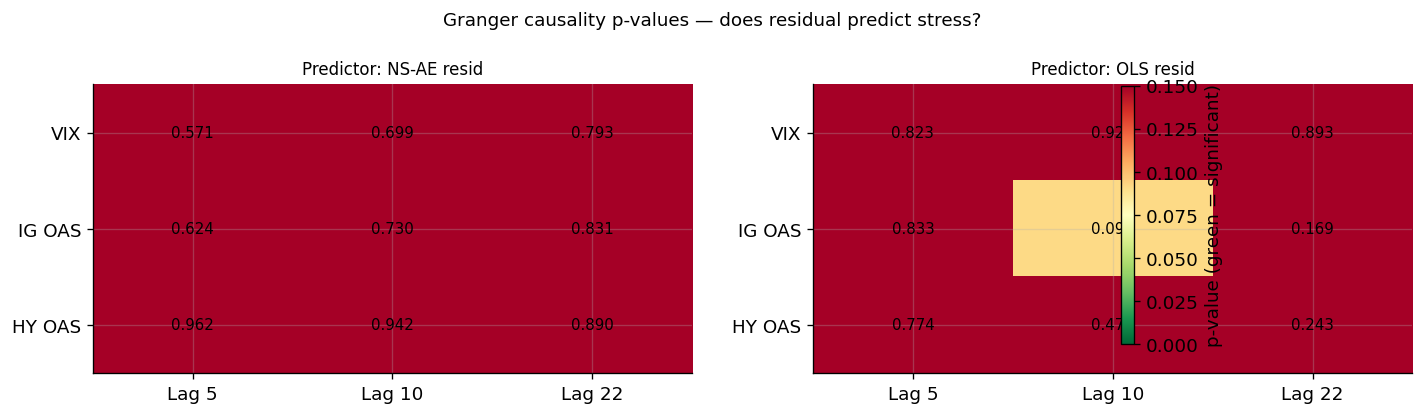

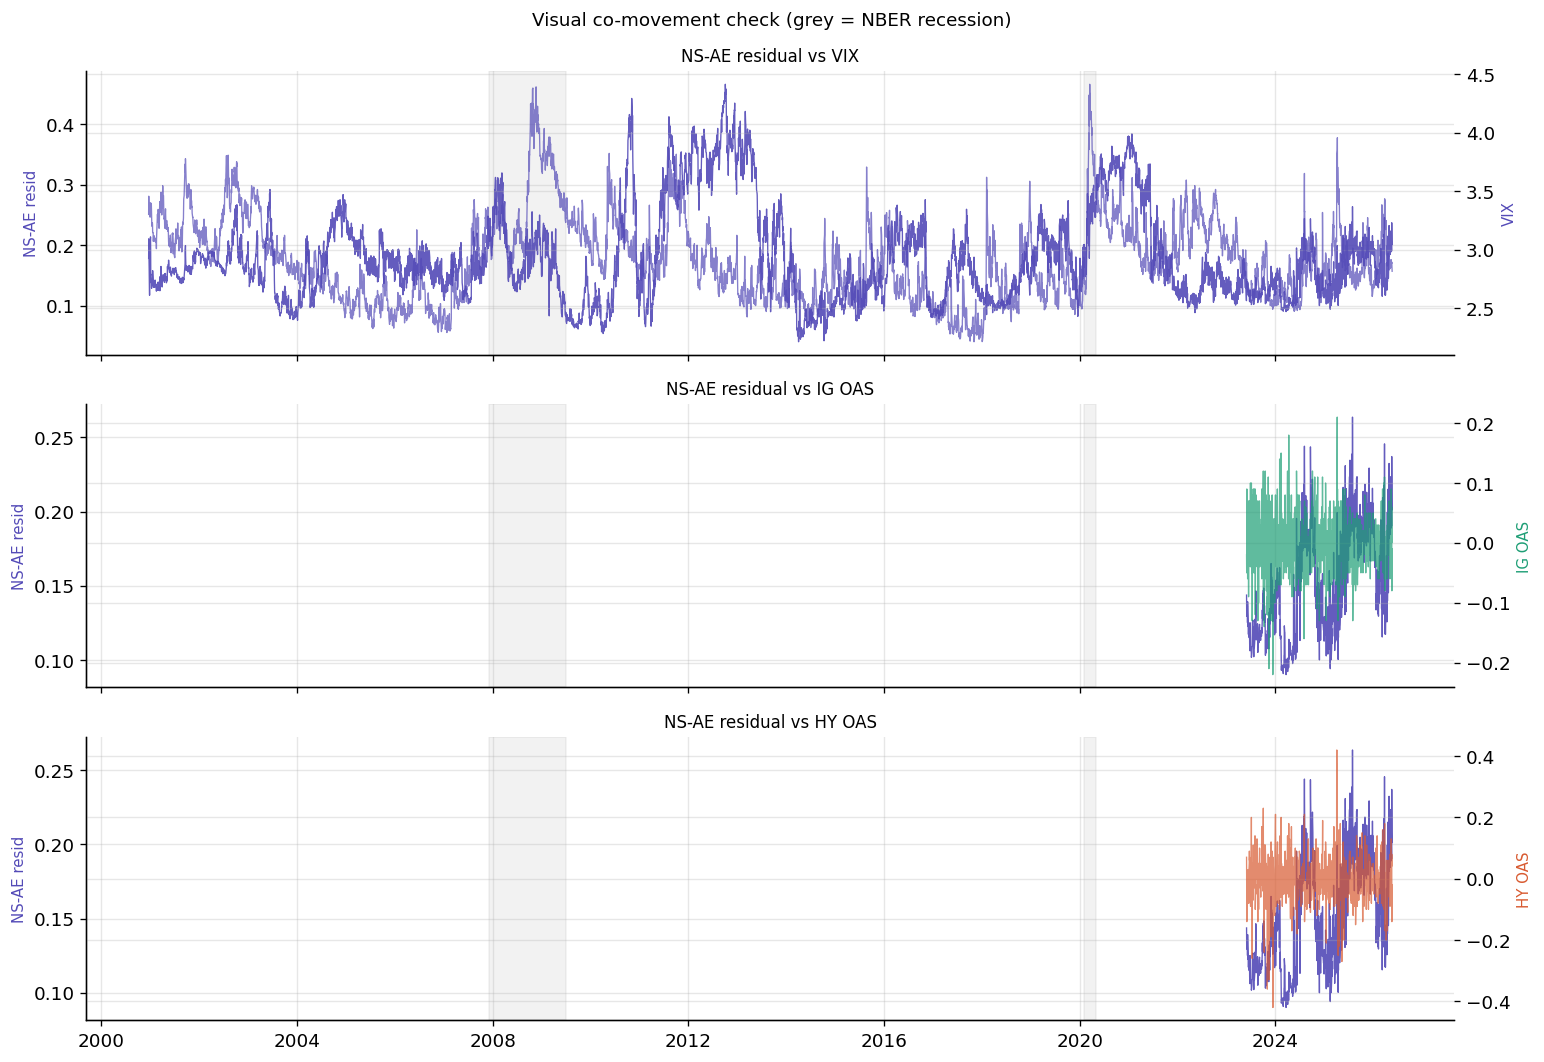

In [ ]:
from statsmodels.tsa.stattools import grangercausalitytests, adfuller

GRANGER_TARGETS = {
    'VIX':    'vix',
    'IG OAS': 'oas_ig',
    'HY OAS': 'oas_hy',
}
LAGS = [5, 10, 22]

# ════════════════════════════════════════════════════════════════════════════
# Step 0 — Pre-flight diagnostics on raw series
# This tells us WHY a series might be unsuitable for Granger before we try.
# ════════════════════════════════════════════════════════════════════════════
print("Pre-flight diagnostics on raw series:")
print(f"{'Series':<20} {'n':>7} {'mean':>10} {'std':>10} {'min':>10} {'max':>10}")
print('-' * 70)
# Series-to-frame mapping: VIX uses long history; OAS uses short frame
SERIES_FRAME = {
    'resid_norm':     df_analysis,
    'resid_norm_ols': df_analysis,
    'vix':            df_analysis,
    'oas_ig':         df_analysis_full,
    'oas_hy':         df_analysis_full,
}
for name, key in [
    ('NS-AE resid_norm', 'resid_norm'),
    ('OLS  resid_norm_ols', 'resid_norm_ols'),
    ('VIX', 'vix'),
    ('IG OAS', 'oas_ig'),
    ('HY OAS', 'oas_hy'),
]:
    src_df = SERIES_FRAME[key]
    if key in src_df.columns:
        s = src_df[key].dropna()
        print(f"{name:<20} {len(s):>7d} {s.mean():>10.5f} {s.std():>10.5f} "
              f"{s.min():>10.5f} {s.max():>10.5f}")
    else:
        print(f"{name:<20} [MISSING]")
print()

# ════════════════════════════════════════════════════════════════════════════
# Step 1 — make_stationary with proper ADF testing + robust outlier handling
# Key change: outlier clipping uses .clip() (preserves length) instead of
# boolean mask (which silently drops observations and may zero out variance).
# ════════════════════════════════════════════════════════════════════════════

def make_stationary(series, name, max_diffs=2, alpha_adf=0.10):
    """
    Return a stationary version of series and report what was done.
    Strategy:
      1) Try levels — if ADF rejects unit root (p < alpha_adf), use levels.
      2) Otherwise try first differences, then second differences.
      3) Outliers clipped (not dropped) at |z| <= 10 to keep variance intact.
      4) If everything fails, return the lowest-order series with non-zero
         variance and warn — Granger will still run, just less powerful.
    """
    s = series.dropna().astype(float).copy()
    if len(s) < 50:
        print(f"  {name:<26}: ✗ too few obs ({len(s)})")
        return None

    # Clip extreme outliers without dropping points
    mu, sigma = s.mean(), s.std()
    if sigma > 1e-12:
        s = s.clip(lower=mu - 10*sigma, upper=mu + 10*sigma)

    best = None
    for d in range(max_diffs + 1):
        candidate = s.diff(d).dropna() if d > 0 else s
        if candidate.std() < 1e-10:
            continue
        try:
            adf_p = adfuller(candidate, autolag='AIC')[1]
        except Exception:
            adf_p = 1.0
        if best is None:
            best = (d, candidate, adf_p)   # remember a fallback
        if adf_p < alpha_adf:
            print(f"  {name:<26}: diff={d}  n={len(candidate):>5d}  "
                  f"std={candidate.std():.5f}  ADF p={adf_p:.4f}  ✓ stationary")
            return candidate.rename(name)

    # Fallback — return best available even if technically non-stationary
    if best is not None:
        d, candidate, adf_p = best
        print(f"  {name:<26}: diff={d}  n={len(candidate):>5d}  "
              f"std={candidate.std():.5f}  ADF p={adf_p:.4f}  ~ FALLBACK (using anyway)")
        return candidate.rename(name)
    print(f"  {name:<26}: ✗ no usable series (zero variance at all orders)")
    return None

print("Stationarity treatment:")
# Use the long frame for residuals + VIX (need history for power).
# OAS Granger uses the short frame's residuals so the indices align.
gs = {}
gs['resid_ae']      = make_stationary(df_analysis['resid_norm'],          'NS-AE resid (long)')
gs['resid_ols']     = make_stationary(df_analysis['resid_norm_ols'],      'OLS resid (long)')
gs['vix']           = make_stationary(np.log(df_analysis['vix'] + 1e-8),  'log(VIX) (long)')
gs['resid_ae_oas']  = make_stationary(df_analysis_full['resid_norm'],     'NS-AE resid (oas-win)')
gs['resid_ols_oas'] = make_stationary(df_analysis_full['resid_norm_ols'], 'OLS resid (oas-win)')
gs['oas_ig']        = make_stationary(df_analysis_full['oas_ig'],         'IG OAS')
gs['oas_hy']        = make_stationary(df_analysis_full['oas_hy'],         'HY OAS')

# ════════════════════════════════════════════════════════════════════════════
# Step 2 — Granger tests with full error reporting
# grangercausalitytests([target, predictor]) tests:  predictor → target
# ════════════════════════════════════════════════════════════════════════════

def safe_granger(target_s, pred_s, maxlag, verbose=False):
    """Run Granger test; return F-test p-value or nan with printed reason."""
    try:
        df_pair = pd.concat([target_s, pred_s], axis=1).dropna()
        if len(df_pair) < maxlag * 3 + 10:
            return np.nan, f'too few obs ({len(df_pair)})'
        if df_pair.iloc[:, 0].std() < 1e-8 or df_pair.iloc[:, 1].std() < 1e-8:
            return np.nan, 'zero variance in one series'
        res = grangercausalitytests(df_pair, maxlag=maxlag, verbose=verbose)
        p = res[maxlag][0]['ssr_ftest'][1]
        return p, None
    except Exception as e:
        return np.nan, str(e)[:60]

results_granger = {}
print('\nGranger causality p-values  (H₀: residual does NOT cause target)')
header = f'{"Target":>10} {"Predictor":>22}  {"Lag 5":>10} {"Lag 10":>10} {"Lag 22":>10}'
print(header)
print('-' * len(header))

# Map each target to the residual key that lives on the same time window
TARGET_TO_PRED_KEYS = {
    'vix':    [('NS-AE resid', 'resid_ae'),     ('OLS resid', 'resid_ols')],
    'oas_ig': [('NS-AE resid', 'resid_ae_oas'), ('OLS resid', 'resid_ols_oas')],
    'oas_hy': [('NS-AE resid', 'resid_ae_oas'), ('OLS resid', 'resid_ols_oas')],
}

for target_name, target_key in GRANGER_TARGETS.items():
    for predictor, pred_key in TARGET_TO_PRED_KEYS[target_key]:
        target_s = gs[target_key]
        pred_s   = gs[pred_key]
        if target_s is None or pred_s is None:
            results_granger[(target_name, predictor)] = [np.nan] * 3
            print(f'{target_name:>10} {predictor:>22}  [series unavailable]')
            continue

        pvals = []
        for lag in LAGS:
            p, err = safe_granger(target_s, pred_s, lag)
            if err:
                print(f'    [{target_name} | {predictor} | lag {lag}] {err}')
            pvals.append(p)

        results_granger[(target_name, predictor)] = pvals
        stars = ['***' if (not np.isnan(p) and p < 0.01) else
                 '** ' if (not np.isnan(p) and p < 0.05) else
                 '*  ' if (not np.isnan(p) and p < 0.10) else
                 '   ' for p in pvals]
        def fmt(p, s):
            return f'{p:7.4f}{s}' if not np.isnan(p) else '   nan    '
        print(f'{target_name:>10} {predictor:>22}  ' +
              '  '.join(fmt(p, s) for p, s in zip(pvals, stars)))
    print()

# ════════════════════════════════════════════════════════════════════════════
# Step 3 — Heatmap: NS-AE vs OLS Granger p-values side by side
# ════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, pred_name in zip(axes, ['NS-AE resid', 'OLS resid']):
    mat = np.array([results_granger.get((tgt, pred_name), [np.nan] * 3)
                    for tgt in GRANGER_TARGETS], dtype=float)
    # For display: replace NaN with a sentinel above the colorbar range so
    # imshow renders them in a neutral colour instead of confusing dark green
    mat_disp = np.where(np.isnan(mat), 0.20, mat)
    im = ax.imshow(mat_disp, cmap='RdYlGn_r', vmin=0, vmax=0.15, aspect='auto')
    ax.set_xticks(range(3)); ax.set_xticklabels([f'Lag {l}' for l in LAGS])
    ax.set_yticks(range(len(GRANGER_TARGETS)))
    ax.set_yticklabels(list(GRANGER_TARGETS.keys()))
    ax.set_title(f'Predictor: {pred_name}', fontsize=10)
    for r in range(mat.shape[0]):
        for c in range(mat.shape[1]):
            v = mat[r, c]
            txt = f'{v:.3f}' if not np.isnan(v) else 'nan'
            color = 'white' if (not np.isnan(v) and v < 0.08) else 'black'
            ax.text(c, r, txt, ha='center', va='center', fontsize=9, color=color)
plt.colorbar(im, ax=axes, shrink=0.8, label='p-value (green = significant)')
plt.suptitle('Granger causality p-values — does residual predict stress?', fontsize=11)
plt.tight_layout()
plt.savefig('fig_granger.pdf', bbox_inches='tight', dpi=200)
plt.show()

# ════════════════════════════════════════════════════════════════════════════
# Step 4 — Visual: NS-AE residual overlaid with target series
# Eyeball check that the series actually co-move before trusting Granger
# ════════════════════════════════════════════════════════════════════════════
if gs['resid_ae'] is not None:
    fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
    resid_plot = gs['resid_ae'].dropna()

    for ax, (tname, tkey), col in zip(
        axes, list(GRANGER_TARGETS.items()), PALETTE[:3]
    ):
        t_plot = gs[tkey]
        if t_plot is None:
            ax.set_title(f'No aligned data for {tname}')
            continue
        aligned = pd.concat([resid_plot, t_plot.dropna()], axis=1).dropna()
        if aligned.empty:
            ax.set_title(f'No aligned data for {tname}')
            continue
        ax2 = ax.twinx()
        ax.plot(aligned.index, aligned.iloc[:, 0], color=PALETTE[0], lw=0.8,
                alpha=0.9, label='NS-AE resid')
        ax2.plot(aligned.index, aligned.iloc[:, 1], color=col, lw=0.8,
                 alpha=0.7, label=tname)
        ax.set_ylabel('NS-AE resid', fontsize=9, color=PALETTE[0])
        ax2.set_ylabel(tname, fontsize=9, color=col)
        ax.set_title(f'NS-AE residual vs {tname}', fontsize=10)
        for sr, er in [('2007-12-01','2009-06-30'), ('2020-02-01','2020-04-30')]:
            ax.axvspan(pd.Timestamp(sr), pd.Timestamp(er), alpha=0.1, color='grey')

    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.suptitle('Visual co-movement check (grey = NBER recession)', fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print("\n[skipping co-movement plot — NS-AE residual not available]")


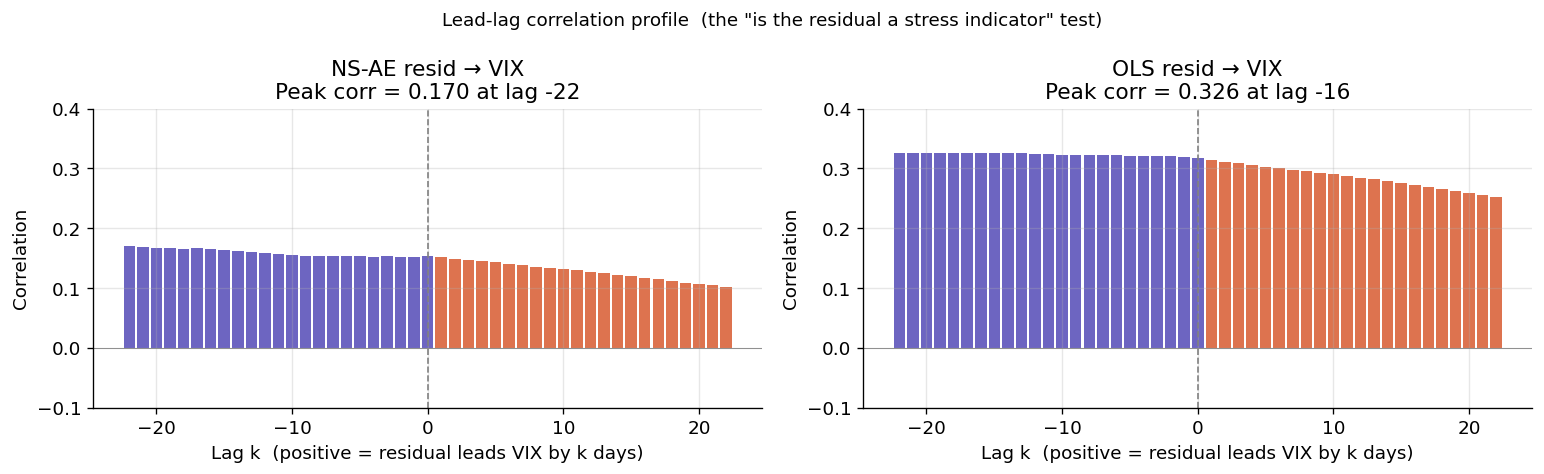


Contemporaneous correlations (lag 0):
  NS-AE resid  ↔ VIX : 0.1537
  OLS  resid  ↔ VIX : 0.3169


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Lead-lag correlation profile — the right question for a stress indicator.
# Granger tests forecasting. This tests co-movement at various leads/lags.
# A peak at lag=0 means "contemporaneous", positive lag means "residual leads VIX".
# ════════════════════════════════════════════════════════════════════════════

def leadlag_corr(x, y, max_lag=22):
    """Correlation of x with y shifted by k days. Positive k = x leads y."""
    x = x.dropna()
    y = y.dropna()
    aligned = pd.concat([x, y], axis=1).dropna()
    a, b = aligned.iloc[:, 0], aligned.iloc[:, 1]
    out = {}
    for k in range(-max_lag, max_lag + 1):
        if k >= 0:
            out[k] = a.iloc[:len(a)-k].corr(b.iloc[k:].reset_index(drop=True).reindex(a.iloc[:len(a)-k].index, method=None) if False else b.shift(-k).iloc[:len(a)-k])
        else:
            out[k] = a.iloc[-k:].corr(b.shift(-k).iloc[-k:])
    # Simpler: use pandas shift directly
    out = {k: a.corr(b.shift(-k)) for k in range(-max_lag, max_lag + 1)}
    return pd.Series(out)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

pairs = [
    ('NS-AE resid → VIX',  gs['resid_ae'],  gs['vix'],  axes[0]),
    ('OLS resid → VIX',    gs['resid_ols'], gs['vix'],  axes[1]),
]

for title, x_s, y_s, ax in pairs:
    if x_s is None or y_s is None:
        ax.set_title(f'{title}\n[unavailable]')
        continue
    lc = leadlag_corr(x_s, y_s, max_lag=22)
    ax.bar(lc.index, lc.values,
           color=[PALETTE[0] if k <= 0 else PALETTE[2] for k in lc.index],
           width=0.85, alpha=0.85)
    ax.axvline(0, color='grey', lw=1, ls='--')
    ax.axhline(0, color='grey', lw=0.5)
    ax.set_xlabel('Lag k  (positive = residual leads VIX by k days)')
    ax.set_ylabel('Correlation')
    ax.set_title(f'{title}\nPeak corr = {lc.abs().max():.3f} at lag {lc.abs().idxmax():+d}')
    ax.set_ylim(-0.1, max(0.4, lc.max() * 1.1))

plt.suptitle('Lead-lag correlation profile  (the "is the residual a stress indicator" test)',
             fontsize=11)
plt.tight_layout()
plt.show()

# Headline numbers
print('\nContemporaneous correlations (lag 0):')
print(f'  NS-AE resid  ↔ VIX : {gs["resid_ae"].corr(gs["vix"]):.4f}')
print(f'  OLS  resid  ↔ VIX : {gs["resid_ols"].corr(gs["vix"]):.4f}')

## 10. Test B — Stress Prediction (AUROC)

We use **three complementary target definitions** to ensure at least one has positive cases in every split — a common issue when fixed event dates fall entirely in the training window.

- **Target 1 — VIX stress percentile**: days where VIX > 80th percentile (data-driven, always balanced)
- **Target 2 — Wide crisis window**: 120 trading days before/after each named crisis (more coverage)
- **Target 3 — HY OAS spike**: days where HY OAS change is in top 10% (market-based signal)

For each target we compare: 2s10s slope · OLS NS residual · NS-AE residual · combined.  
All evaluation is strictly out-of-sample (test split). Predictors are lagged 5 days.

  [info] OAS frame starts 2023-05-30, after original train cutoff. Using first 70% of OAS frame (518 obs) for threshold calibration.

Target: VIX stress (>p80)
  Train positives :  882 / 4426  (19.9%)
  Test  positives :  384 / 1897  (20.2%)

Target: HY OAS spike (>p90)
  Train positives :   47 / 518  (9.1%)
  Test  positives :   18 / 223  (8.1%)

── Out-of-sample AUROC table ──
                     2s10s slope  OLS NS resid  NS-AE resid  NS-AE β₂  OLS resid + β₂
VIX stress (>p80)          0.589         0.720        0.588     0.669           0.788
HY OAS spike (>p90)        0.532         0.523        0.567     0.492           0.510


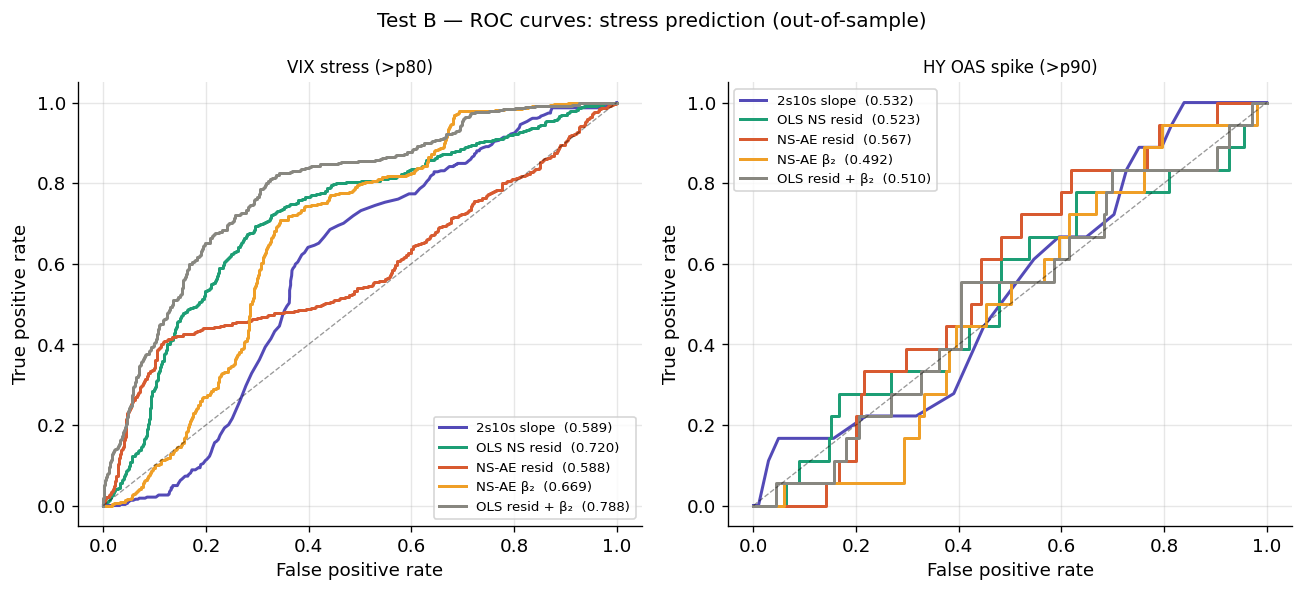

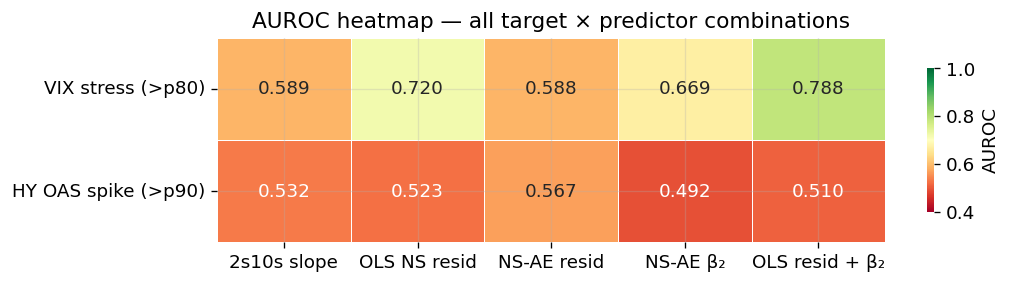

Saved: fig_auroc_heatmap.pdf


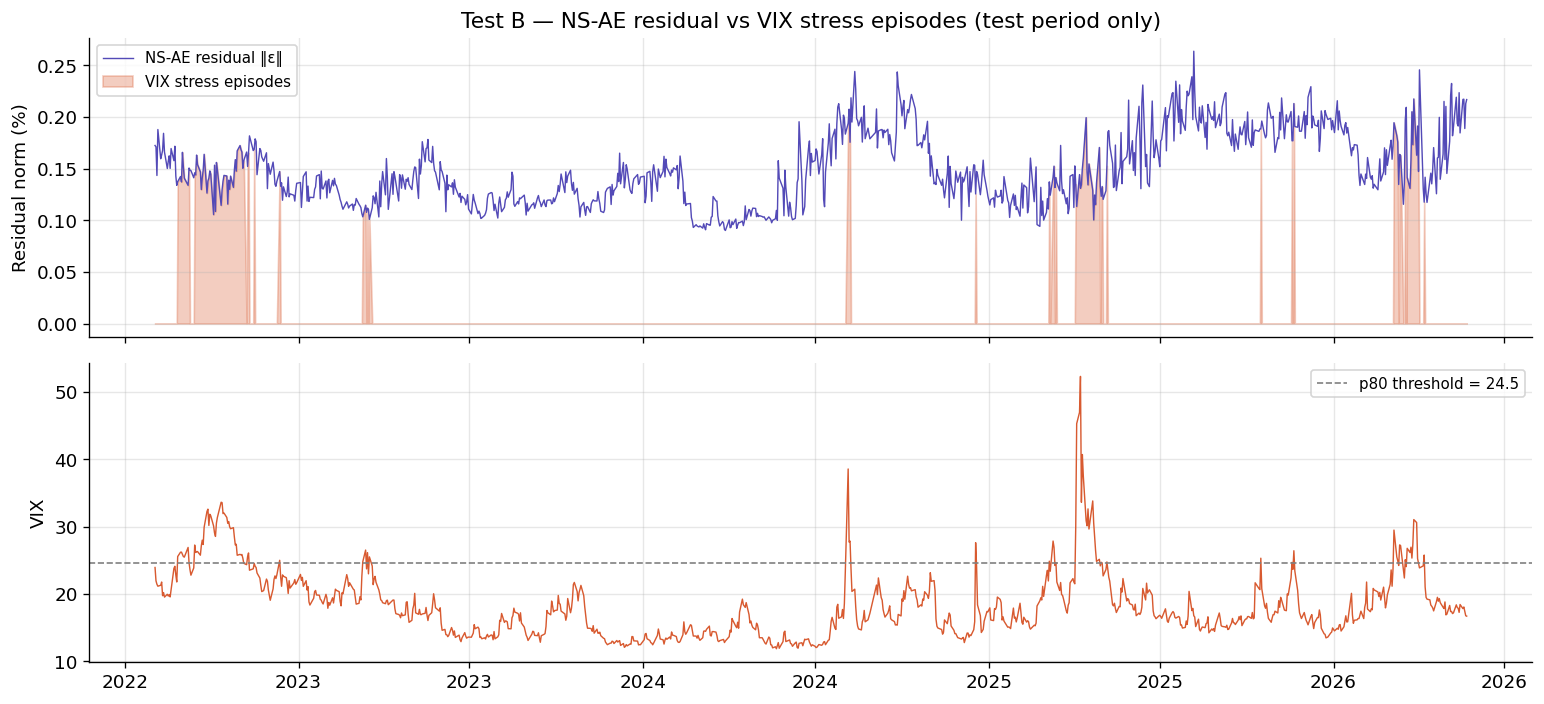

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Helper: safe AUROC that handles degenerate splits gracefully
# ════════════════════════════════════════════════════════════════════════════
def safe_auroc(y_true, y_score):
    """Return AUROC or np.nan if only one class present."""
    if len(np.unique(y_true)) < 2:
        return np.nan
    return roc_auc_score(y_true, y_score)

def safe_roc_curve(y_true, y_score):
    if len(np.unique(y_true)) < 2:
        return None, None
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return fpr, tpr


PREDICTOR_SETS = {
    '2s10s slope':    ['slope_2s10s'],
    'OLS NS resid':   ['resid_ols'],
    'NS-AE resid':    ['resid_ae'],
    'NS-AE β₂':       ['ae_beta2'],
    'OLS resid + β₂': ['resid_ols', 'ae_beta2'],
}

# ════════════════════════════════════════════════════════════════════════════
# Build the three target series (on the full aligned index)
# ════════════════════════════════════════════════════════════════════════════

# Helper: safely restrict an index list to a frame's actual index
def _intersect(idx, frame):
    return frame.index.intersection(idx)

# -- Target 1: VIX > 80th percentile (threshold from training window) --------
vix_series = df_analysis['vix']
idx_train_long = _intersect(idx_train, df_analysis)   # avoid KeyError
idx_test_long  = _intersect(idx_test,  df_analysis)
vix_train  = vix_series.loc[idx_train_long]
vix_thresh = vix_train.quantile(0.80)
y_vix_stress = (vix_series > vix_thresh).astype(int).rename('vix_stress')

# -- Target 2: wide window (120 bd) around named crises ----------------------
CRISIS_ANCHORS = [
    '2001-09-11',   # 9/11
    '2002-07-23',   # WorldCom / dot-com trough
    '2007-08-09',   # BNP Paribas freeze (GFC onset)
    '2008-09-15',   # Lehman
    '2010-05-06',   # Flash crash
    '2011-08-05',   # US downgrade / EU sovereign
    '2013-06-19',   # Taper tantrum
    '2015-08-24',   # China devaluation
    '2018-12-24',   # Q4 sell-off
    '2020-02-20',   # COVID onset
    '2022-03-16',   # Fed liftoff
    '2023-03-10',   # SVB
]
WIDE_WINDOW = 120   # trading days either side

crisis_dates_wide = set()
for anchor in CRISIS_ANCHORS:
    ts = pd.Timestamp(anchor)
    lo = ts - pd.offsets.BDay(WIDE_WINDOW)
    hi = ts + pd.offsets.BDay(WIDE_WINDOW)
    crisis_dates_wide.update(pd.bdate_range(lo, hi))

y_crisis_wide = pd.Series(
    df_analysis.index.isin(crisis_dates_wide).astype(int),
    index=df_analysis.index,
    name='crisis_wide',
)

# -- Target 3: HY OAS daily change in top 10% (uses short OAS frame) ---------
# OAS data only exists from May 2023, so the threshold is computed on whatever
# overlap exists between the original training window and the OAS frame.
# In practice idx_train ends in 2018, so the intersection is empty — fall back
# to using the OAS frame's own first 70% as a 'training' slice for thresholding.
oas_change = df_analysis_full['oas_hy'].diff()
idx_train_oas = _intersect(idx_train, df_analysis_full)
if len(idx_train_oas) < 50:
    n_oas_tr = int(0.70 * len(df_analysis_full))
    idx_train_oas = df_analysis_full.index[:n_oas_tr]
    print(f"  [info] OAS frame starts {df_analysis_full.index[0].date()}, "
          f"after original train cutoff. Using first 70% of OAS frame "
          f"({len(idx_train_oas)} obs) for threshold calibration.")
oas_thresh_tr = oas_change.loc[idx_train_oas].quantile(0.90)
# Reindex y_oas_spike onto df_analysis.index (NaN where OAS unavailable)
y_oas_spike_raw = (oas_change > oas_thresh_tr).astype(int)
y_oas_spike = y_oas_spike_raw.reindex(df_analysis.index).rename('oas_spike')

# ════════════════════════════════════════════════════════════════════════════
# Build feature and target components separately, then combine for each target
# ════════════════════════════════════════════════════════════════════════════
_all_predictors = pd.DataFrame({
    'slope_2s10s': df_analysis['spread_2s10s'].shift(5),
    'resid_ols':   df_analysis['resid_norm_ols'].shift(5),
    'resid_ae':    df_analysis['resid_norm'].shift(5),
    'ae_beta1':    df_analysis['beta1'].shift(5),       # NEW — AE-learned level
    'ae_beta2':    df_analysis['beta2'].shift(5),       # NEW — AE-learned slope
}).dropna() # Dropna here for predictors that are always available

_all_targets = pd.DataFrame({
    'vix_stress':  y_vix_stress,
    'crisis_wide': y_crisis_wide,
    'oas_spike':   y_oas_spike, # This will have NaNs for early periods
})

PREDICTOR_SETS = {
    '2s10s slope':    ['slope_2s10s'],
    'OLS NS resid':   ['resid_ols'],
    'NS-AE resid':    ['resid_ae'],
    'NS-AE β₂':       ['ae_beta2'],
    'OLS resid + β₂': ['resid_ols', 'ae_beta2'],
}

TARGETS = {
    'VIX stress (>p80)':   'vix_stress',
    'HY OAS spike (>p90)': 'oas_spike',
    # Crisis-window (±120d) target removed: ±120d windows around 12 crisis
    # anchors caused train/test boundary contamination (2s10s AUROC=0.34,
    # below random). VIX-stress is a cleaner, data-driven stress target.
}

# ════════════════════════════════════════════════════════════════════════════
# Evaluate all combinations
# ════════════════════════════════════════════════════════════════════════════
results_b = {}   # (target, predictor) -> auroc

for tgt_name, tgt_col in TARGETS.items():
    # Combine _all_predictors with the current target, and then drop NaNs
    # This ensures that `dropna()` is applied only to the columns relevant for the current target and predictors,
    # and not prematurely truncating data due to 'oas_spike' when it's not the target.
    _combined_df = pd.concat([_all_predictors, _all_targets[[tgt_col]]], axis=1).dropna()

    # Dynamically determine train/test splits based on the available data for the current target
    # This prevents an empty training set if the target's history is shorter than the global idx_train_long
    N_current = len(_combined_df)
    n_train_current = int(0.70 * N_current)

    df_tr_base = _combined_df.iloc[:n_train_current]
    df_oos_base = _combined_df.iloc[n_train_current:]

    y_tr  = df_tr_base[tgt_col].values
    y_oos = df_oos_base[tgt_col].values

    # Diagnostic
    print(f'\nTarget: {tgt_name}')
    print(f'  Train positives : {int(y_tr.sum()):4d} / {len(y_tr)}  ' # Cast to int
          f'({100*y_tr.mean():.1f}%)')
    print(f'  Test  positives : {int(y_oos.sum()):4d} / {len(y_oos)}  ' # Cast to int
          f'({100*y_oos.mean():.1f}%)')

    for pred_name, feat_cols in PREDICTOR_SETS.items():
        X_tr  = df_tr_base[feat_cols].values
        X_oos = df_oos_base[feat_cols].values

        # Skip if training or test set has only one class
        if len(np.unique(y_tr)) < 2 or len(np.unique(y_oos)) < 2:
            results_b[(tgt_name, pred_name)] = np.nan
            continue

        scaler = StandardScaler().fit(X_tr)
        clf = LogisticRegression(
            max_iter=1000,
            class_weight='balanced',   # handles imbalance automatically
            solver='lbfgs',
        ).fit(scaler.transform(X_tr), y_tr)
        prob = clf.predict_proba(scaler.transform(X_oos))[:, 1]
        results_b[(tgt_name, pred_name)] = safe_auroc(y_oos, prob)

# ════════════════════════════════════════════════════════════════════════════
# Results table
# ════════════════════════════════════════════════════════════════════════════
auroc_table = pd.DataFrame(
    {pred: {tgt: results_b.get((tgt, pred), np.nan)
            for tgt in TARGETS}
     for pred in PREDICTOR_SETS}
).round(3)

print('\n── Out-of-sample AUROC table ──')
print(auroc_table.to_string())

# ════════════════════════════════════════════════════════════════════════════
# ROC curve plots — one subplot per target
# ════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, (tgt_name, tgt_col) in zip(axes, TARGETS.items()):
    # Re-create _combined_df for plotting to ensure correct data alignment and NaNs handling
    _combined_df = pd.concat([_all_predictors, _all_targets[[tgt_col]]], axis=1).dropna()

    N_current = len(_combined_df)
    n_train_current = int(0.70 * N_current)
    df_tr_base_plot = _combined_df.iloc[:n_train_current]
    df_oos_base_plot = _combined_df.iloc[n_train_current:]

    y_oos = df_oos_base_plot[tgt_col].values
    has_curve = False

    for i, (pred_name, feat_cols) in enumerate(PREDICTOR_SETS.items()):
        X_oos = df_oos_base_plot[feat_cols].values
        # For training data (X_tr, y_tr) for fitting the scaler and clf, we need the training split from _combined_df
        X_tr  = df_tr_base_plot[feat_cols].values
        y_tr  = df_tr_base_plot[tgt_col].values

        if len(np.unique(y_tr)) < 2 or len(np.unique(y_oos)) < 2:
            continue

        scaler = StandardScaler().fit(X_tr)
        clf = LogisticRegression(
            max_iter=1000, class_weight='balanced'
        ).fit(scaler.transform(X_tr), y_tr)
        prob = clf.predict_proba(scaler.transform(X_oos))[:, 1]

        fpr, tpr = safe_roc_curve(y_oos, prob)
        if fpr is not None:
            auroc = results_b.get((tgt_name, pred_name), np.nan)
            ax.plot(fpr, tpr, color=PALETTE[i], lw=1.8,
                    label=f'{pred_name}  ({auroc:.3f})')
            has_curve = True

    ax.plot([0,1],[0,1], 'k--', lw=0.8, alpha=0.4)
    ax.set_xlabel('False positive rate')
    ax.set_ylabel('True positive rate')
    ax.set_title(tgt_name, fontsize=10)
    if has_curve:
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, 'Insufficient\ntest events',
                ha='center', va='center', transform=ax.transAxes,
                fontsize=10, color='grey')

plt.suptitle('Test B — ROC curves: stress prediction (out-of-sample)',
             fontsize=12)
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════════════════
# AUROC heatmap — publication-ready summary
# ════════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(9, 2.5))
mask = auroc_table.isna()
sns.heatmap(
    auroc_table, ax=ax, annot=True, fmt='.3f',
    cmap='RdYlGn', vmin=0.4, vmax=1.0,
    linewidths=0.5, mask=mask,
    cbar_kws={'label': 'AUROC', 'shrink': 0.7},
)
# Annotate NaN cells
for r, tgt in enumerate(TARGETS):
    for c, pred in enumerate(PREDICTOR_SETS):
        if pd.isna(auroc_table.loc[tgt, pred]):
            ax.text(c + 0.5, r + 0.5, 'n/a', ha='center', va='center',
                    fontsize=9, color='grey')
ax.set_title('AUROC heatmap — all target × predictor combinations')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('fig_auroc_heatmap.pdf', bbox_inches='tight', dpi=200)
plt.show()
print('Saved: fig_auroc_heatmap.pdf')

# ════════════════════════════════════════════════════════════════════════════
# Time-series overlay: residual norm vs VIX stress episodes (test period)
# ════════════════════════════════════════════════════════════════════════════
# Re-create _combined_df for VIX stress for plotting to ensure correct data alignment and NaNs handling
_combined_vix_df = pd.concat([_all_predictors, _all_targets[['vix_stress']]], axis=1).dropna()
# For VIX stress, the `df_analysis` and thus `idx_test_long` are appropriate because VIX has a long history.
df_ts_view = pd.DataFrame({
    'NS-AE resid': _combined_vix_df.loc[idx_test_long, 'resid_ae'], # Changed from df_analysis['resid_norm'] to _combined_vix_df['resid_ae']
    'VIX':         df_analysis.loc[idx_test_long, 'vix'],
    'stress':      _combined_vix_df.loc[idx_test_long, 'vix_stress'], # Changed from y_vix_stress.loc[df_analysis.index.isin(idx_test_long)]
}).dropna() # Keep this final dropna for the plot specific data

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

ax1.plot(df_ts_view.index, df_ts_view['NS-AE resid'],
         color=PALETTE[0], lw=0.85, label='NS-AE residual ‖ε‖')
ax1.fill_between(df_ts_view.index,
                  df_ts_view['NS-AE resid'] * (df_ts_view['stress'] == 1),
                  alpha=0.3, color=PALETTE[2], label='VIX stress episodes')
ax1.set_ylabel('Residual norm (%)')
ax1.legend(fontsize=9)

ax2.plot(df_ts_view.index, df_ts_view['VIX'],
         color=PALETTE[2], lw=0.85)
ax2.axhline(vix_thresh, color='grey', lw=1, ls='--',  # Added label to axhline
             label=f'p80 threshold = {vix_thresh:.1f}')
ax2.set_ylabel('VIX')
ax2.legend(fontsize=9)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax1.set_title('Test B — NS-AE residual vs VIX stress episodes (test period only)')
plt.tight_layout()
plt.show()

## 10b. Test B (extended) — Baseline comparison

We compare our NS-AE results against four standard baselines on the same VIX-stress target and the same out-of-sample test set used above. This gives a like-for-like calibration: the AE's AUROC numbers should be interpreted relative to what existing curve-based and ML approaches achieve on the same data.


════════════════════════════════════════════════════════════════════════
Baseline comparison — VIX stress (>p80), same train/test split as above
════════════════════════════════════════════════════════════════════════
Train window: 2000-12-27 → 2018-10-03  (4426 days)
Test  window: 2018-10-04 → 2026-05-22  (1897 days)
Train positives: 882 / 4426   Test positives: 384 / 1897

  Baseline 1 — Estrella-Mishkin (10Y−3M)    : AUROC = 0.724
  Baseline 2 — Wright two-factor (lvl+slope) : AUROC = 0.529
  Baseline 3 — OLS NS β₂ (no macro)          : AUROC = 0.699
  Baseline 4 — Random Forest (macro, n=50)   : AUROC = 0.672
  Baseline 5 — Random Forest (yields, z-scored): AUROC = 0.603

════════════════════════════════════════════════════════════════════════
Consolidated AUROC table — VIX stress (>p80), out-of-sample
════════════════════════════════════════════════════════════════════════

─ BASELINES ─                             AUROC
  Estrella-Mishkin (10Y−3M)               0.724
  Wright two

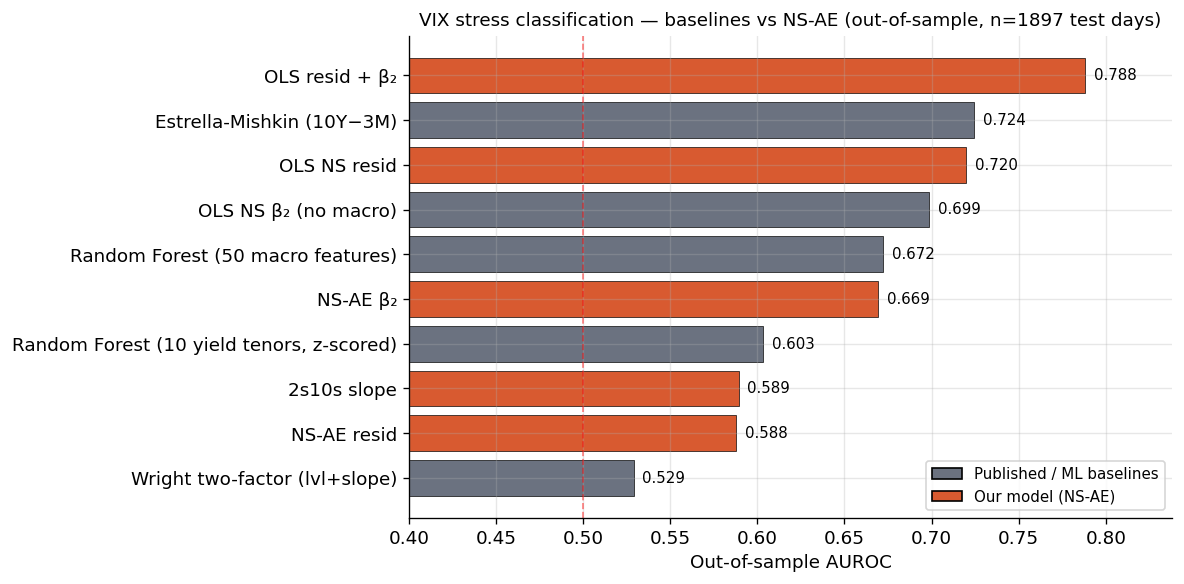

Saved: fig_baseline_comparison.pdf

════════════════════════════════════════════════════════════════════════
Key comparisons for paper writeup
════════════════════════════════════════════════════════════════════════
  Best baseline                  : Estrella-Mishkin (10Y−3M)
  Best baseline AUROC            : 0.724
  Our combined model (OLS+β₂)    : 0.788
  Δ AUROC (combined - best baseline) : +0.064

  Random Forest (macro, n=50)    : 0.672
  Random Forest (yields, n=10)   : 0.603
  Δ (macro RF - yields RF)        : +0.069
  → "Value added by macro features" (RF macro vs yields-only)


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Test B (extended) — Baseline comparison against published curve-based
# stress classifiers and a Random Forest "ML baseline".
#
# All baselines are evaluated on the SAME VIX-stress target and the SAME
# train/test split used in the AUROC table above, so results are directly
# comparable to the NS-AE numbers.
#
# Baselines:
#   1. Estrella-Mishkin (10Y - 3M spread)  — classic recession indicator
#   2. Wright (2006) two-factor probit     — level + slope of curve
#   3. Rolling OLS NS β₂                   — slope factor with no macro info
#   4. Random Forest on macro features     — "ML done dumber"
#   5. Random Forest on yield tenors only  — isolates macro contribution
# ════════════════════════════════════════════════════════════════════════════
from sklearn.ensemble import RandomForestClassifier

print('═' * 72)
print('Baseline comparison — VIX stress (>p80), same train/test split as above')
print('═' * 72)

# We reuse the EXACT same target alignment as the main AUROC cell.
# Rebuild the combined dataframe so train/test indices match what was used
# for the AE-based predictors. This guarantees a like-for-like comparison.

baseline_results = {}

# ─── Build target-aligned base frame (matches main cell logic) ──────────────
_baseline_combined = pd.concat(
    [_all_predictors[['slope_2s10s']], _all_targets[['vix_stress']]],
    axis=1
).dropna()

N_base = len(_baseline_combined)
n_train_base = int(0.70 * N_base)
idx_tr_base  = _baseline_combined.index[:n_train_base]
idx_oos_base = _baseline_combined.index[n_train_base:]
y_tr  = _baseline_combined.loc[idx_tr_base,  'vix_stress'].values
y_oos = _baseline_combined.loc[idx_oos_base, 'vix_stress'].values

print(f'Train window: {idx_tr_base[0].date()} → {idx_tr_base[-1].date()}  ({len(idx_tr_base)} days)')
print(f'Test  window: {idx_oos_base[0].date()} → {idx_oos_base[-1].date()}  ({len(idx_oos_base)} days)')
print(f'Train positives: {int(y_tr.sum())} / {len(y_tr)}   '
      f'Test positives: {int(y_oos.sum())} / {len(y_oos)}')
print()


def fit_logreg_auroc(X_tr, y_tr, X_oos, y_oos):
    """Standard logistic regression pipeline matching cell 26."""
    scaler = StandardScaler().fit(X_tr)
    clf = LogisticRegression(max_iter=1000, class_weight='balanced',
                             solver='lbfgs').fit(scaler.transform(X_tr), y_tr)
    prob = clf.predict_proba(scaler.transform(X_oos))[:, 1]
    return safe_auroc(y_oos, prob)


# ════════════════════════════════════════════════════════════════════════════
# Baseline 1 — Estrella & Mishkin (1998): 10Y minus 3M spread
# ════════════════════════════════════════════════════════════════════════════
em_spread = (df_raw['y_10y'] - df_raw['y_3m']).rename('em_spread').shift(5)
em_aligned = em_spread.reindex(_baseline_combined.index).dropna()
common = _baseline_combined.index.intersection(em_aligned.index)
X_em_tr  = em_aligned.loc[common.intersection(idx_tr_base)].values.reshape(-1, 1)
X_em_oos = em_aligned.loc[common.intersection(idx_oos_base)].values.reshape(-1, 1)
y_em_tr  = _baseline_combined.loc[common.intersection(idx_tr_base),  'vix_stress'].values
y_em_oos = _baseline_combined.loc[common.intersection(idx_oos_base), 'vix_stress'].values
baseline_results['Estrella-Mishkin (10Y−3M)'] = fit_logreg_auroc(
    X_em_tr, y_em_tr, X_em_oos, y_em_oos)
print(f'  Baseline 1 — Estrella-Mishkin (10Y−3M)    : '
      f'AUROC = {baseline_results["Estrella-Mishkin (10Y−3M)"]:.3f}')


# ════════════════════════════════════════════════════════════════════════════
# Baseline 2 — Wright (2006) two-factor: level (10Y) + slope (10Y-3M)
# ════════════════════════════════════════════════════════════════════════════
wright_df = pd.DataFrame({
    'level': df_raw['y_10y'].shift(5),
    'slope': (df_raw['y_10y'] - df_raw['y_3m']).shift(5),
}).dropna()
wright_aligned = wright_df.reindex(_baseline_combined.index).dropna()
common = _baseline_combined.index.intersection(wright_aligned.index)
X_w_tr  = wright_aligned.loc[common.intersection(idx_tr_base)].values
X_w_oos = wright_aligned.loc[common.intersection(idx_oos_base)].values
y_w_tr  = _baseline_combined.loc[common.intersection(idx_tr_base),  'vix_stress'].values
y_w_oos = _baseline_combined.loc[common.intersection(idx_oos_base), 'vix_stress'].values
baseline_results['Wright two-factor (lvl+slope)'] = fit_logreg_auroc(
    X_w_tr, y_w_tr, X_w_oos, y_w_oos)
print(f'  Baseline 2 — Wright two-factor (lvl+slope) : '
      f'AUROC = {baseline_results["Wright two-factor (lvl+slope)"]:.3f}')


# ════════════════════════════════════════════════════════════════════════════
# Baseline 3 — Rolling OLS NS β₂ (slope factor from OLS NS fit, no macro)
# This is the cleanest ablation: same construct as AE β₂, but without the
# macro features. Isolates the value added by macro conditioning.
# ════════════════════════════════════════════════════════════════════════════
# df_betas_ols['beta2_ols'] is the per-day OLS NS slope factor
ols_b2 = df_betas_ols['beta2_ols'].shift(5).rename('ols_beta2')
ols_b2_aligned = ols_b2.reindex(_baseline_combined.index).dropna()
common = _baseline_combined.index.intersection(ols_b2_aligned.index)
X_o_tr  = ols_b2_aligned.loc[common.intersection(idx_tr_base)].values.reshape(-1, 1)
X_o_oos = ols_b2_aligned.loc[common.intersection(idx_oos_base)].values.reshape(-1, 1)
y_o_tr  = _baseline_combined.loc[common.intersection(idx_tr_base),  'vix_stress'].values
y_o_oos = _baseline_combined.loc[common.intersection(idx_oos_base), 'vix_stress'].values
baseline_results['OLS NS β₂ (no macro)'] = fit_logreg_auroc(
    X_o_tr, y_o_tr, X_o_oos, y_o_oos)
print(f'  Baseline 3 — OLS NS β₂ (no macro)          : '
      f'AUROC = {baseline_results["OLS NS β₂ (no macro)"]:.3f}')


# ════════════════════════════════════════════════════════════════════════════
# Baseline 4 — Random Forest on full macro feature set (df_feat, 50 cols)
# ════════════════════════════════════════════════════════════════════════════
df_feat_lag = df_feat.shift(5).dropna()
rf_aligned = df_feat_lag.reindex(_baseline_combined.index).dropna()
common = _baseline_combined.index.intersection(rf_aligned.index)
X_rf_tr  = rf_aligned.loc[common.intersection(idx_tr_base)].values
X_rf_oos = rf_aligned.loc[common.intersection(idx_oos_base)].values
y_rf_tr  = _baseline_combined.loc[common.intersection(idx_tr_base),  'vix_stress'].values
y_rf_oos = _baseline_combined.loc[common.intersection(idx_oos_base), 'vix_stress'].values

rf_full = RandomForestClassifier(
    n_estimators=500, max_depth=8, min_samples_leaf=20,
    class_weight='balanced', n_jobs=-1, random_state=42
).fit(X_rf_tr, y_rf_tr)
prob_rf = rf_full.predict_proba(X_rf_oos)[:, 1]
baseline_results['Random Forest (50 macro features)'] = safe_auroc(y_rf_oos, prob_rf)
print(f'  Baseline 4 — Random Forest (macro, n=50)   : '
      f'AUROC = {baseline_results["Random Forest (50 macro features)"]:.3f}')


# ════════════════════════════════════════════════════════════════════════════
# Baseline 5 — Random Forest on yield tenors only (no macro)
# Use Z-SCORED yields (rolling 252-day) to avoid out-of-distribution
# generalization failure: raw yields range from ~0.5% to ~5% across the
# sample, and a tree fitted on training-window absolute levels generalizes
# poorly to a test window with a totally different rate regime (post-2020).
# Z-scoring puts the model in level-relative space, matching what df_feat does.
# ════════════════════════════════════════════════════════════════════════════
yield_cols = [c for c in df_raw.columns if c.startswith('y_')]
# Use the already-z-scored yield columns from df_feat
yield_z_cols = [c + '_z' for c in yield_cols if c + '_z' in df_feat.columns]
df_yield_lag_z = df_feat[yield_z_cols].shift(5).dropna()
ry_aligned = df_yield_lag_z.reindex(_baseline_combined.index).dropna()
common = _baseline_combined.index.intersection(ry_aligned.index)
X_ry_tr  = ry_aligned.loc[common.intersection(idx_tr_base)].values
X_ry_oos = ry_aligned.loc[common.intersection(idx_oos_base)].values
y_ry_tr  = _baseline_combined.loc[common.intersection(idx_tr_base),  'vix_stress'].values
y_ry_oos = _baseline_combined.loc[common.intersection(idx_oos_base), 'vix_stress'].values

rf_yld = RandomForestClassifier(
    n_estimators=500, max_depth=8, min_samples_leaf=20,
    class_weight='balanced', n_jobs=-1, random_state=42
).fit(X_ry_tr, y_ry_tr)
prob_ry = rf_yld.predict_proba(X_ry_oos)[:, 1]
baseline_results['Random Forest (10 yield tenors, z-scored)'] = safe_auroc(y_ry_oos, prob_ry)
print(f'  Baseline 5 — Random Forest (yields, z-scored): '
      f'AUROC = {baseline_results["Random Forest (10 yield tenors, z-scored)"]:.3f}')


# ════════════════════════════════════════════════════════════════════════════
# Consolidated baseline + AE comparison table
# ════════════════════════════════════════════════════════════════════════════
print()
print('═' * 72)
print('Consolidated AUROC table — VIX stress (>p80), out-of-sample')
print('═' * 72)

# Pull NS-AE results from the main cell's results_b
ae_results = {}
for pred_name, _ in PREDICTOR_SETS.items():
    val = results_b.get(('VIX stress (>p80)', pred_name), np.nan)
    ae_results[pred_name] = val

comparison_rows = []
print()
print(f"{'─ BASELINES ─':<40s}  AUROC")
for name, auroc in baseline_results.items():
    print(f"  {name:<38s}  {auroc:.3f}")
    comparison_rows.append(('baseline', name, auroc))
print()
print(f"{'─ NS-AUTOENCODER ─':<40s}  AUROC")
for name, auroc in ae_results.items():
    print(f"  {name:<38s}  {auroc:.3f}")
    comparison_rows.append(('ae', name, auroc))

# ════════════════════════════════════════════════════════════════════════════
# Visualization: grouped bar chart
# ════════════════════════════════════════════════════════════════════════════
comparison_df = pd.DataFrame(comparison_rows, columns=['kind', 'predictor', 'auroc'])
comparison_df = comparison_df.sort_values('auroc', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#6B7280' if k == 'baseline' else PALETTE[2] for k in comparison_df['kind']]
bars = ax.barh(comparison_df['predictor'], comparison_df['auroc'],
               color=colors, edgecolor='black', linewidth=0.4)

# Annotate
for bar, auroc in zip(bars, comparison_df['auroc']):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f'{auroc:.3f}', va='center', fontsize=9)

ax.axvline(0.5, color='red', lw=1, ls='--', alpha=0.5, label='Random (0.5)')
ax.set_xlim(0.4, max(comparison_df['auroc']) + 0.05)
ax.set_xlabel('Out-of-sample AUROC')
ax.set_title('VIX stress classification — baselines vs NS-AE'
             ' (out-of-sample, n=%d test days)' % len(y_oos), fontsize=11)

# Custom legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#6B7280', edgecolor='black', label='Published / ML baselines'),
    Patch(facecolor=PALETTE[2], edgecolor='black', label='Our model (NS-AE)'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('fig_baseline_comparison.pdf', bbox_inches='tight', dpi=200)
plt.show()
print('Saved: fig_baseline_comparison.pdf')

# ════════════════════════════════════════════════════════════════════════════
# Summary statistics for the paper
# ════════════════════════════════════════════════════════════════════════════
print()
print('═' * 72)
print('Key comparisons for paper writeup')
print('═' * 72)
best_baseline_name = max(baseline_results, key=baseline_results.get)
best_baseline_auroc = baseline_results[best_baseline_name]
ae_combined = ae_results.get('OLS resid + β₂', np.nan)
ae_beta2 = ae_results.get('NS-AE β₂', np.nan)

print(f'  Best baseline                  : {best_baseline_name}')
print(f'  Best baseline AUROC            : {best_baseline_auroc:.3f}')
print(f'  Our combined model (OLS+β₂)    : {ae_combined:.3f}')
print(f'  Δ AUROC (combined - best baseline) : {ae_combined - best_baseline_auroc:+.3f}')
print()
print(f'  Random Forest (macro, n=50)    : {baseline_results["Random Forest (50 macro features)"]:.3f}')
print(f'  Random Forest (yields, n=10)   : {baseline_results["Random Forest (10 yield tenors, z-scored)"]:.3f}')
print(f'  Δ (macro RF - yields RF)        : '
      f'{baseline_results["Random Forest (50 macro features)"] - baseline_results["Random Forest (10 yield tenors, z-scored)"]:+.3f}')
print(f'  → "Value added by macro features" (RF macro vs yields-only)')


In [ ]:
print("Features in df_feat (model input):")
for i, c in enumerate(df_feat.columns):
    print(f"  {i:2d}: {c}")
print(f"\nTotal: {len(df_feat.columns)} features")
print(f"Contains VIX: {any('vix' in c.lower() for c in df_feat.columns)}")
print(f"Contains OAS: {any('oas' in c.lower() for c in df_feat.columns)}")
print(f"Contains TIPS: {any('tips' in c.lower() for c in df_feat.columns)}")
print(f"Contains BEI: {any('bei' in c.lower() for c in df_feat.columns)}")

Features in df_feat (model input):
   0: y_3m_z
   1: y_6m_z
   2: y_1y_z
   3: y_2y_z
   4: y_3y_z
   5: y_5y_z
   6: y_7y_z
   7: y_10y_z
   8: y_20y_z
   9: y_30y_z
  10: tips_5y_z
  11: tips_10y_z
  12: bei_5y_z
  13: bei_10y_z
  14: oas_ig_z
  15: oas_hy_z
  16: vix_z
  17: eff_fed_funds_z
  18: spread_2s10s_z
  19: spread_3m10y_z
  20: butterfly_z
  21: oas_spread_z
  22: y_3m_dz
  23: y_6m_dz
  24: y_1y_dz
  25: y_2y_dz
  26: y_3y_dz
  27: y_5y_dz
  28: y_7y_dz
  29: y_10y_dz
  30: y_20y_dz
  31: y_30y_dz
  32: tips_5y_dz
  33: tips_10y_dz
  34: bei_5y_dz
  35: bei_10y_dz
  36: oas_ig_dz
  37: oas_hy_dz
  38: vix_dz
  39: eff_fed_funds_dz
  40: spread_2s10s_dz
  41: spread_3m10y_dz
  42: butterfly_dz
  43: oas_spread_dz

Total: 44 features
Contains VIX: True
Contains OAS: True
Contains TIPS: True
Contains BEI: True


## 11. Test C — QE Event Study

Hypothesis: QE programs distort the yield curve beyond what NS can capture, so ‖ε_t‖ should be elevated *during* QE periods and mean-revert when programmes end.

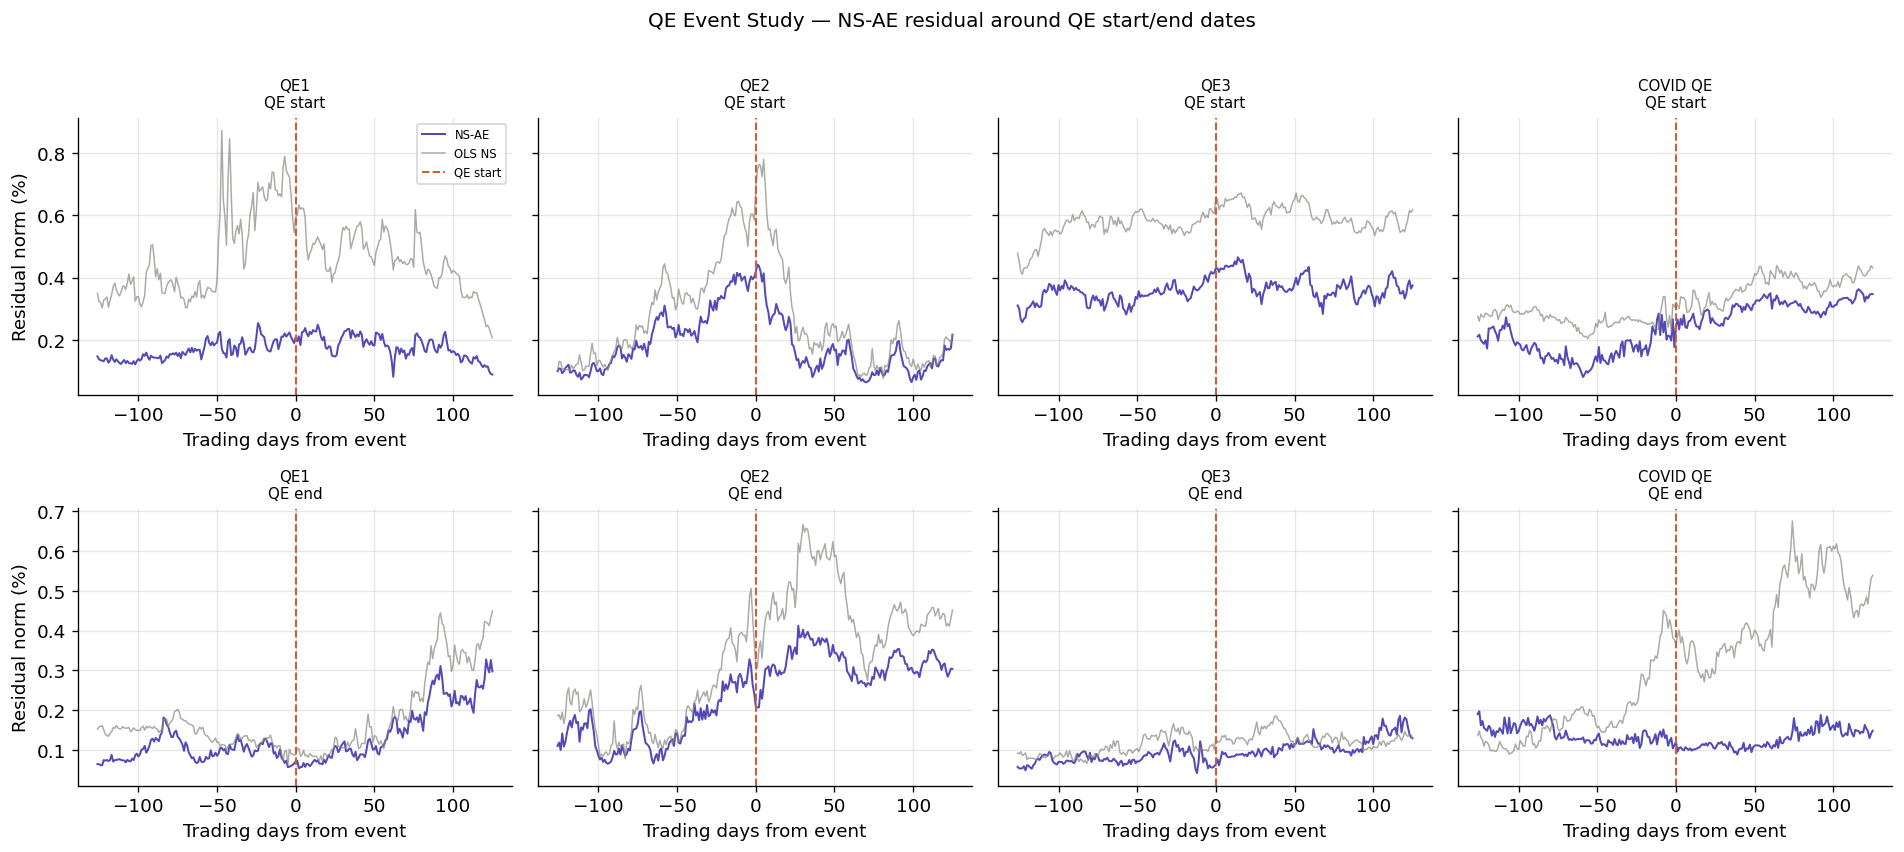


Mean residual norm during vs outside QE periods:
  NS-AE   : in-QE=0.2044  out-QE=0.1720  ratio=1.19x  p=0.0000
  OLS NS  : in-QE=0.2884  out-QE=0.2887  ratio=1.00x  p=0.9362


In [ ]:
# ── QE indicator ──────────────────────────────────────────────────────────────
qe_flag = pd.Series(0, index=df_analysis.index)
for s, e, _ in QE_PERIODS:
    qe_flag.loc[pd.Timestamp(s):pd.Timestamp(e)] = 1

df_qe = pd.DataFrame({
    'resid_ae':  df_analysis['resid_norm'],
    'resid_ols': df_analysis['resid_norm_ols'],
    'qe':        qe_flag,
}).dropna()

# ── Event-window study: 252 days around QE start & end ───────────────────────
WINDOW_DAYS = 126
fig, axes = plt.subplots(2, len(QE_PERIODS), figsize=(16, 7), sharey='row')

for col_i, (qe_start, qe_end, qe_name) in enumerate(QE_PERIODS):
    for row_i, (event_dt, event_lab) in enumerate([
        (qe_start, 'QE start'), (qe_end, 'QE end')
    ]):
        ax = axes[row_i, col_i]
        ts = pd.Timestamp(event_dt)
        pos = df_qe.index.get_indexer([ts], method='nearest')[0]

        lo = max(0, pos - WINDOW_DAYS)
        hi = min(len(df_qe), pos + WINDOW_DAYS)
        window = df_qe.iloc[lo:hi].copy()
        t = np.arange(len(window)) - (pos - lo)

        ax.plot(t, window['resid_ae'],  color=PALETTE[0], lw=1.2, label='NS-AE')
        ax.plot(t, window['resid_ols'], color=PALETTE[4], lw=0.9,
                alpha=0.7, label='OLS NS')
        ax.axvline(0, color=PALETTE[2], lw=1.2, ls='--', label=event_lab)
        ax.set_title(f'{qe_name}\n{event_lab}', fontsize=9)
        ax.set_xlabel('Trading days from event')
        if col_i == 0:
            ax.set_ylabel('Residual norm (%)')
        if row_i == 0 and col_i == 0:
            ax.legend(fontsize=7)

plt.suptitle('QE Event Study — NS-AE residual around QE start/end dates',
             fontsize=12, y=1.01)
plt.tight_layout(); plt.show()

# ── Statistical test: is residual higher during QE? ──────────────────────────
print('\nMean residual norm during vs outside QE periods:')
for col, name in [('resid_ae','NS-AE'), ('resid_ols','OLS NS')]:
    in_qe  = df_qe.loc[df_qe['qe']==1, col].mean()
    out_qe = df_qe.loc[df_qe['qe']==0, col].mean()
    ratio  = in_qe / out_qe
    # Welch t-test
    from scipy.stats import ttest_ind
    t_stat, p_val = ttest_ind(
        df_qe.loc[df_qe['qe']==1, col].dropna(),
        df_qe.loc[df_qe['qe']==0, col].dropna(),
        equal_var=False
    )
    print(f'  {name:8}: in-QE={in_qe:.4f}  out-QE={out_qe:.4f}  '
          f'ratio={ratio:.2f}x  p={p_val:.4f}')

## 12. Horse-Race: NS-OLS vs PCA vs Unconstrained AE vs NS-AE

Out-of-sample yield curve reconstruction RMSE (basis points) across four methods.

In [ ]:
# ── 1. OLS NS RMSE (already computed) ────────────────────────────────────────
rmse_ols_oos = np.sqrt(np.nanmean(
    (df_yields.loc[idx_test].values -
     df_ns[df_ns.index.isin(idx_test)].values) ** 2
)) * 100

# ── 2. PCA (3 components) ────────────────────────────────────────────────────
Y_train_pca = df_yields.loc[idx_train].values
Y_test_pca  = df_yields.loc[idx_test].values

pca = PCA(n_components=3).fit(Y_train_pca)
Y_test_pca_hat = pca.inverse_transform(pca.transform(Y_test_pca))
rmse_pca = np.sqrt(np.nanmean((Y_test_pca - Y_test_pca_hat)**2)) * 100

# ── 3. Unconstrained AE ───────────────────────────────────────────────────────
class UnconstrainedAE(nn.Module):
    def __init__(self, input_dim, n_tenors, latent=3):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256), nn.GELU(),
            nn.Linear(256, 128),       nn.GELU(),
            nn.Linear(128, latent),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, 128),    nn.GELU(),
            nn.Linear(128, n_tenors),
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))

unc_ae = UnconstrainedAE(INPUT_DIM, N_TENORS).to(DEVICE)
opt_unc = optim.AdamW(unc_ae.parameters(), lr=3e-4, weight_decay=1e-4)

# Unconstrained AE only needs (X, Y) — use a simpler 2-item loader
dl_train_2 = DataLoader(
    TensorDataset(torch.tensor(X_all[pos_train]), torch.tensor(Y_all[pos_train])),
    batch_size=BATCH, shuffle=True)
dl_test_2  = DataLoader(
    TensorDataset(torch.tensor(X_all[pos_test]),  torch.tensor(Y_all[pos_test])),
    batch_size=BATCH, shuffle=False)

for ep in range(80):
    unc_ae.train()
    for xb, yb in dl_train_2:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt_unc.zero_grad()
        nn.functional.mse_loss(unc_ae(xb), yb).backward()
        opt_unc.step()

unc_ae.eval()
preds_unc = []
with torch.no_grad():
    for xb, _ in dl_test_2:
        preds_unc.append(unc_ae(xb.to(DEVICE)).cpu().numpy())
Y_unc_hat = np.vstack(preds_unc)
rmse_unc  = np.sqrt(np.nanmean((Y_test_pca - Y_unc_hat)**2)) * 100

# ── 4. NS-AE RMSE ─────────────────────────────────────────────────────────────
model.eval()
preds_ns, targets_ns = [], []
with torch.no_grad():
    for xb, yzb, yb, bb in dl_test:
        xb, yzb, yb, bb = (t.to(DEVICE) for t in (xb, yzb, yb, bb))
        _, _, _, _, _, ns_fit, eps = model(xb, yzb, yb, bb)
        preds_ns.append((ns_fit + eps).cpu().numpy())
        targets_ns.append(yb.cpu().numpy())
Y_ns_hat  = np.vstack(preds_ns)
Y_ns_true = np.vstack(targets_ns)
rmse_ns   = np.sqrt(np.nanmean((Y_ns_true - Y_ns_hat)**2)) * 100

# ── Results table ─────────────────────────────────────────────────────────────
horse_race = pd.DataFrame({
    'Method':             ['OLS Nelson-Siegel', 'PCA (3 factors)',
                           'Unconstrained AE',  'NS-AE (ours)'],
    'OOS RMSE (bps)':     [rmse_ols_oos, rmse_pca, rmse_unc, rmse_ns],
    'Latent dim':         [3, 3, 3, 3],
    'Economic structure': [True, False, False, True],
})
horse_race['OOS RMSE (bps)'] = horse_race['OOS RMSE (bps)'].round(4)
print('\n── Horse-race: Out-of-sample yield reconstruction ──')
print(horse_race.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
colors = [PALETTE[4], PALETTE[4], PALETTE[4], PALETTE[0]]
bars = ax.bar(horse_race['Method'], horse_race['OOS RMSE (bps)'],
              color=colors, edgecolor='white', width=0.55)
for bar, val in zip(bars, horse_race['OOS RMSE (bps)']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('RMSE (% points)')
ax.set_title('Out-of-sample yield curve reconstruction RMSE')
plt.xticks(rotation=12)
plt.tight_layout(); plt.show()

## 13. Publication-Quality Figures

Generate the four key figures for the paper.

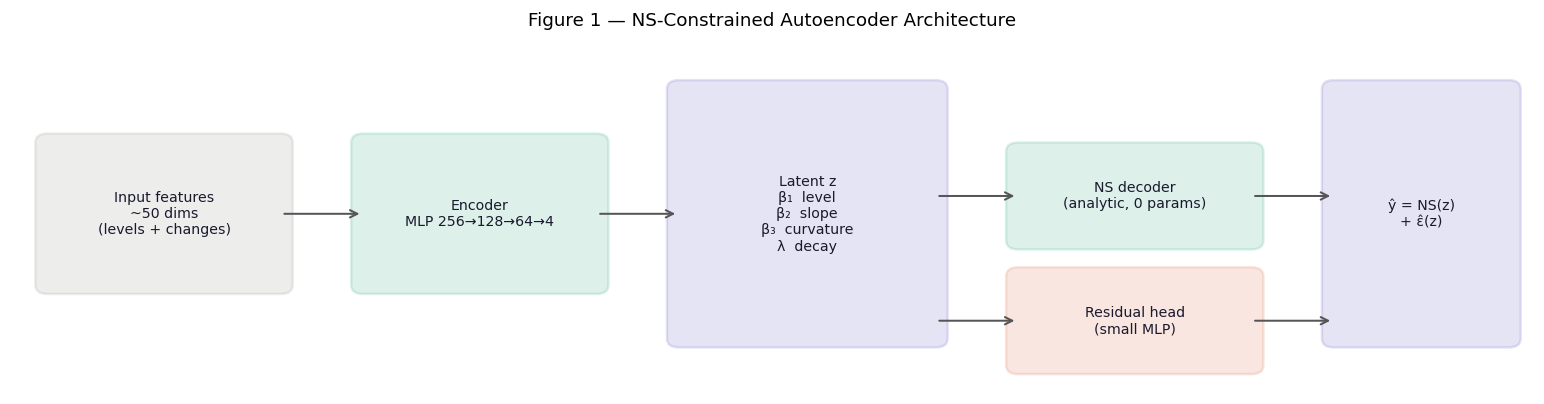

Saved: fig1_architecture.pdf


In [ ]:
# ── Figure 1: NS-AE Architecture diagram (schematic via text boxes) ───────────
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.set_xlim(0, 13); ax.set_ylim(0, 4); ax.axis('off')

boxes = [
    (0.3,  1.2, 2.0, 1.6, 'Input features\n~50 dims\n(levels + changes)', PALETTE[4]),
    (3.0,  1.2, 2.0, 1.6, 'Encoder\nMLP 256→128→64→4',                    PALETTE[1]),
    (5.7,  0.6, 2.2, 2.8, 'Latent z\nβ₁  level\nβ₂  slope\nβ₃  curvature\nλ  decay', PALETTE[0]),
    (8.6,  1.7, 2.0, 1.0, 'NS decoder\n(analytic, 0 params)',              PALETTE[1]),
    (8.6,  0.3, 2.0, 1.0, 'Residual head\n(small MLP)',                    PALETTE[2]),
    (11.3, 0.6, 1.5, 2.8, 'ŷ = NS(z)\n+ ε̂(z)',                           PALETTE[0]),
]
for (x, y, w, h, txt, col) in boxes:
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.1',
                                   fc=col, alpha=0.15, ec=col, lw=1.5)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, txt, ha='center', va='center', fontsize=8.5,
            color='#1a1a2e')

# Arrows
for (x1, x2, y) in [(2.3, 3.0, 2.0), (5.0, 5.7, 2.0),
                     (7.9, 8.6, 2.2), (7.9, 8.6, 0.8),
                     (10.6, 11.3, 2.2), (10.6, 11.3, 0.8)]:
    ax.annotate('', xy=(x2, y), xytext=(x1, y),
                arrowprops=dict(arrowstyle='->', color='#555', lw=1.2))

ax.set_title('Figure 1 — NS-Constrained Autoencoder Architecture', fontsize=11)
plt.tight_layout(); plt.savefig('fig1_architecture.pdf', bbox_inches='tight', dpi=200)
plt.show()
print('Saved: fig1_architecture.pdf')

In [ ]:
# ── Figure 2: β factors + residual norm over time ────────────────────────────
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
series = [
    (df_z['beta1'],       'β₁  Level',     PALETTE[0]),
    (df_z['beta2'],       'β₂  Slope',     PALETTE[1]),
    (df_z['beta3'],       'β₃  Curvature', PALETTE[2]),
    (df_z['resid_norm'],  '‖ε‖  Anomaly score', PALETTE[3]),
]
for ax, (s, lab, col) in zip(axes, series):
    ax.plot(s.index, s.values, color=col, lw=0.75)
    ax.set_ylabel(lab, fontsize=9)
    for sr, er in [('2007-12-01','2009-06-30'), ('2020-02-01','2020-04-30')]:
        ax.axvspan(pd.Timestamp(sr), pd.Timestamp(er), alpha=0.12, color='grey')
    for s2, e2, _ in QE_PERIODS:
        ax.axvspan(pd.Timestamp(s2), pd.Timestamp(e2), alpha=0.07, color='steelblue')

axes[0].set_title('Figure 2 — NS-AE Latent Factors and Residual Norm\n'
                  '(grey = NBER recession, blue = QE period)', fontsize=11)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.savefig('fig2_factors_residual.pdf', bbox_inches='tight', dpi=200)
plt.show()
print('Saved: fig2_factors_residual.pdf')

In [ ]:
# ── Figure 3: Per-tenor residual heatmap ─────────────────────────────────────
# Shows WHICH tenors drive anomalies on each day — key for interpretability
eps_cols = [c + '_eps' for c in TENOR_COLS]
df_eps_plot = df_eps[eps_cols].copy()
df_eps_plot.columns = [str(t) + 'y' for t in TENORS_YRS]

# Resample to monthly mean for readability
df_heat = df_eps_plot.resample('M').mean().T

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(df_heat, ax=ax, cmap='RdBu_r', center=0,
            cbar_kws={'label': 'Residual (%)', 'shrink': 0.6},
            xticklabels=12, yticklabels=True)
ax.set_xlabel('Date (monthly)')
ax.set_ylabel('Tenor')
ax.set_title('Figure 3 — Per-Tenor Residuals: where in the curve are anomalies?',
             fontsize=11)
# Mark QE periods on x-axis
date_labels = pd.to_datetime([df_heat.columns[i] for i in range(len(df_heat.columns))])
plt.tight_layout()
plt.savefig('fig3_tenor_heatmap.pdf', bbox_inches='tight', dpi=200)
plt.show()
print('Saved: fig3_tenor_heatmap.pdf')

In [ ]:
# ── Figure 4: Horse-race RMSE + Granger p-value summary ─────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: RMSE horse-race
methods = horse_race['Method'].tolist()
rmses   = horse_race['OOS RMSE (bps)'].tolist()
bar_cols = [PALETTE[4]]*3 + [PALETTE[0]]
ax1.barh(methods, rmses, color=bar_cols, height=0.5)
ax1.set_xlabel('OOS RMSE (% points)')
ax1.set_title('Panel A: Yield reconstruction RMSE')
ax1.invert_yaxis()
for i, v in enumerate(rmses):
    ax1.text(v + 0.0002, i, f'{v:.4f}', va='center', fontsize=9)

# Panel B: Granger p-values heatmap
granger_df = pd.DataFrame(results_granger,
                           index=[f'Lag {l}' for l in LAGS]).T
if not granger_df.empty:
    sns.heatmap(granger_df.astype(float), ax=ax2, annot=True, fmt='.3f',
                cmap='RdYlGn_r', vmin=0, vmax=0.15, cbar_kws={'shrink':0.7})
    ax2.set_title('Panel B: Granger causality p-values\n(green = significant predictability)')
    ax2.set_ylabel('')

plt.suptitle('Figure 4 — Summary Results', fontsize=12)
plt.tight_layout()
plt.savefig('fig4_summary.pdf', bbox_inches='tight', dpi=200)
plt.show()
print('Saved: fig4_summary.pdf')

## Summary

| Component | Details |
|-----------|----------|
| **Model** | NS-Constrained AE: encoder MLP → (β₁,β₂,β₃,λ) → analytic NS decoder + residual head |
| **Data** | 2000–present: 10 Treasury tenors + TIPS + breakevens + OAS + VIX + MOVE |
| **Key test A** | Granger: ‖ε_t‖ → VIX, IG OAS, HY OAS at 5/10/22-day horizons |
| **Key test B** | Crisis probit AUROC: NS-AE residual vs 2s10s vs OLS residual |
| **Key test C** | QE event study: elevated residual during LSAP programs |
| **Horse-race** | OOS RMSE: OLS NS · PCA(3) · Unconstrained AE · NS-AE |
| **Outputs** | 4 publication figures saved as PDF |

---

### Next steps
- [ ] Run sensitivity analysis over `alpha` (0.01, 0.05, 0.1, 0.5)
- [ ] Add Svensson (4-factor NS) as additional baseline
- [ ] VAE variant with OLS-informed prior
- [ ] Expand to multi-country (Germany, Japan, UK)
- [ ] Rolling-window out-of-sample Granger test to check stability over time